# Experiment R + P: Retraining and numerical privacy metrics
## Extension of the study: Privacy–Security Trade-off in the IDS feature space
 
### Motivation
The basic experiments (S0–S4, E5, E6) evaluate a **frozen pre-trained model** on transformed data.
This measures the model's dependence on the specific representation, but does NOT answer the question:
*Would a model trained directly on anonymized data achieve better detection?*
 
### Experiment R — Retraining per scenario
For each scenario Si:
1. Apply the transformation to the **train set**
2. Train a new DNN of the same architecture from scratch
3. Apply the same transformation to the **test set**
4. Evaluate the retrained model on the transformed test set
5. Compare: frozen model vs retrained model
 
### Experiment P — Numerical privacy metrics
Complements the qualitative WP29 test with:
- **Normalized entropy** per feature group
- **Uniqueness score** (proxy for singling-out risk)
- **k-Anonymity proxy** (minimum equivalence class size)
- **Reconstruction risk** (how well the original port can be reconstructed from the bucket)


## 0. Imports and paths

In [1]:
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow import keras
from sklearn import metrics
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

print(f"TensorFlow: {tf.__version__}")
print(f"Pandas:     {pd.__version__}")
print(f"NumPy:      {np.__version__}")


TensorFlow: 2.15.0
Pandas:     3.0.3
NumPy:      1.26.4


In [2]:
# === PROMENI OVO u svoju putanju ===
PATH = r'C:\Users\AndjelaPC\Documents\ids-anonymization'
# ====================================

test_set  = pd.read_parquet(PATH + "/testset.parquet",  engine="pyarrow")
train_set = pd.read_parquet(PATH + "/trainset.parquet", engine="pyarrow")

print(f"Test set shape:  {test_set.shape}")
print(f"Train set shape: {train_set.shape}")

# Frozen model (originalni, pre-trained)
frozen_model = tf.keras.models.load_model(PATH + "/savedmodel/savedmodel")
print("\nFrozen model učitan!")

attributenum    = len(test_set.columns) - 15
X_test_orig     = test_set.iloc[:, 0:attributenum].copy()
X_train_orig    = train_set.iloc[:, 0:attributenum].copy()
y_test          = test_set.iloc[:, -15:]
y_train         = train_set.iloc[:, -15:]
y_true          = np.argmax(y_test.to_numpy(), axis=1)
y_train_labels  = np.argmax(y_train.to_numpy(), axis=1)

CLASS_NAMES       = list(y_test.columns)
CLASS_NAMES_CLEAN = [c.replace('Label_', '') for c in CLASS_NAMES]
N_CLASSES         = len(CLASS_NAMES_CLEAN)
N_FEATURES        = attributenum

print(f"\nBroj feature-a:  {N_FEATURES}")
print(f"Broj klasa:      {N_CLASSES}")
print(f"Klase: {CLASS_NAMES_CLEAN}")

Test set shape:  (565576, 92)
Train set shape: (2262300, 92)






Frozen model učitan!

Broj feature-a:  77
Broj klasa:      15
Klase: ['BENIGN', 'Bot', 'DDoS', 'DoSGoldenEye', 'DoSHulk', 'DoSSlowhttptest', 'DoSslowloris', 'FTP-Patator', 'Heartbleed', 'Infiltration', 'PortScan', 'SSH-Patator', 'WebAttack-BruteForce', 'WebAttack-SqlInjection', 'WebAttack-XSS']


## 1. Defining transformations (same as in the main experiment)

In [3]:
# ─── Grupe feature-a ─────────────────────────────────────────────────────────
GROUP_TEMPORAL = [
    'FlowIATMean', 'FlowIATStd', 'FlowIATMax', 'FlowIATMin',
    'FwdIATTotal', 'FwdIATMean', 'FwdIATStd', 'FwdIATMax', 'FwdIATMin',
    'BwdIATTotal', 'BwdIATMean', 'BwdIATStd', 'BwdIATMax', 'BwdIATMin',
    'ActiveMean',  'ActiveStd',  'ActiveMax',  'ActiveMin',
    'IdleMean',    'IdleStd',    'IdleMax',    'IdleMin'
]
GROUP_OS_FINGERPRINT = [
    'FwdHeaderLength', 'BwdHeaderLength',
    'SYNFlagCount', 'RSTFlagCount',
    'Init_Win_bytes_forward', 'Init_Win_bytes_backward',
    'min_seg_size_forward'
]
GROUP_STRICT_KEEP = [
    'FlowDuration', 'TotalFwdPackets', 'TotalBackwardPackets',
    'FlowBytes/s', 'FlowPackets/s', 'AveragePacketSize',
    'Down/UpRatio', 'FwdPackets/s', 'BwdPackets/s'
]

def zero_out(X, features):
    X2 = X.copy()
    for col in features:
        if col in X2.columns:
            X2[col] = 0
    return X2

def port_bucket(p):
    if p <= 1023:    return 0
    elif p <= 49151: return 1
    else:            return 2

def apply_port_bucketing(X):
    X2 = X.copy()
    if 'DestinationPort' in X2.columns:
        X2['DestinationPort'] = X2['DestinationPort'].apply(port_bucket)
    return X2

def apply_temporal_gen(X, bin_us=10_000):
    X2 = X.copy()
    for col in GROUP_TEMPORAL:
        if col in X2.columns:
            X2[col] = (X2[col] / bin_us).round() * bin_us
    return X2

def apply_s0(X): return X.copy()
def apply_s1(X): return apply_port_bucketing(X)
def apply_s2(X): return apply_temporal_gen(apply_s1(X), 10_000)
def apply_s3(X): return zero_out(apply_s2(X), GROUP_OS_FINGERPRINT)
def apply_s4(X):
    X2 = apply_s3(X)
    for col in X2.columns:
        if col not in GROUP_STRICT_KEEP:
            X2[col] = 0
    return X2

SCENARIOS = {
    'S0': apply_s0,
    'S1': apply_s1,
    'S2': apply_s2,
    'S3': apply_s3,
    'S4': apply_s4,
}

print("Transformacije definisane.")

Transformacije definisane.


## 2. Model architecture for retraining
 
We use the same architecture as the original model from [Milošević & Ćirić, 2022].
The model is built from scratch for each scenario — no weight transfer.

In [4]:
def build_model(n_features, n_classes):
    """
    Arhitektura identična originalnom modelu (Dense 90 → 50 → 15).
    """
    model = keras.Sequential([
        keras.layers.Input(shape=(n_features,)),
        keras.layers.Dense(90, activation='relu'),
        keras.layers.Dense(50, activation='relu'),
        keras.layers.Dense(n_classes, activation='softmax')
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

# Prikaži arhitekturu
demo_model = build_model(N_FEATURES, N_CLASSES)
demo_model.summary()
print("\nArhitektura identična originalnom modelu.")

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 90)                7020      
                                                                 
 dense_1 (Dense)             (None, 50)                4550      
                                                                 
 dense_2 (Dense)             (None, 15)                765       
                                                                 
Total params: 12335 (48.18 KB)
Trainable params: 12335 (48.18 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________

Arhitektura identična originalnom modelu.


In [5]:
# Prikaži originalnu arhitekturu za poređenje
print("ORIGINALNI (FROZEN) MODEL:")
frozen_model.summary()

ORIGINALNI (FROZEN) MODEL:
Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 90)                7020      
                                                                 
 dense_1 (Dense)             (None, 50)                4550      
                                                                 
 dense_2 (Dense)             (None, 15)                765       
                                                                 
Total params: 12335 (48.18 KB)
Trainable params: 12335 (48.18 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


## 3. Evaluating the frozen model (reference values)
This replicates the results from the main experiment — it serves as a reference for comparison.

In [6]:
def evaluate_model(model, X, y_true_labels, label=""):
    """Evaluacija modela i vraćanje metrika."""
    y_pred_raw = model.predict(X, verbose=0)
    y_pred     = np.argmax(y_pred_raw, axis=1)
    report     = metrics.classification_report(
        y_true_labels, y_pred,
        target_names=CLASS_NAMES_CLEAN,
        digits=4, output_dict=True, zero_division=0
    )
    acc = metrics.accuracy_score(y_true_labels, y_pred)
    mf1 = report['macro avg']['f1-score']
    wf1 = report['weighted avg']['f1-score']
    if label:
        print(f"  {label:<40} Acc={acc:.4f}  MacroF1={mf1:.4f}  WeightedF1={wf1:.4f}")
    return {'accuracy': acc, 'macro_f1': mf1, 'weighted_f1': wf1, 'report': report}


print("Evaluacija frozen modela po scenarijima (referentne vrednosti)...\n")
frozen_results = {}
for s_name, transform_fn in SCENARIOS.items():
    X_transformed = transform_fn(X_test_orig)
    frozen_results[s_name] = evaluate_model(
        frozen_model, X_transformed, y_true,
        label=f"FROZEN  {s_name}"
    )

print("\nFrozen evaluacija završena.")

Evaluacija frozen modela po scenarijima (referentne vrednosti)...

  FROZEN  S0                               Acc=0.9962  MacroF1=0.7206  WeightedF1=0.9959
  FROZEN  S1                               Acc=0.9288  MacroF1=0.5024  WeightedF1=0.9460
  FROZEN  S2                               Acc=0.8777  MacroF1=0.2840  WeightedF1=0.8966
  FROZEN  S3                               Acc=0.7873  MacroF1=0.1082  WeightedF1=0.7562
  FROZEN  S4                               Acc=0.3296  MacroF1=0.0355  WeightedF1=0.4267

Frozen evaluacija završena.


## 4. Experiment R — Retraining per scenario
 
For each scenario:
1. Transform the train set
2. Train a new model of the same architecture
3. Transform the test set (same transformation)
4. Evaluate
 
⏳ **Warning: this may take 30–90 minutes** (5 models × ~10 epochs × 2.2M rows).
We recommend running it overnight or on a GPU.

In [7]:
# Callback-ovi za trening
def get_callbacks(scenario_name):
    return [
        keras.callbacks.EarlyStopping(
            monitor='val_loss',
            patience=3,           # zaustavi ako nema poboljšanja 3 epohe
            restore_best_weights=True,
            verbose=1
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss',
            factor=0.5,
            patience=2,
            verbose=0
        ),
        keras.callbacks.ModelCheckpoint(
            filepath=PATH + f"/retrained_{scenario_name}.keras",
            save_best_only=True,
            verbose=0
        )
    ]

print("Callback-ovi definisani.")
print(f"Maksimalni broj epoha po modelu: 15 (early stopping verovatno kraće)")
print(f"Veličina train seta: {X_train_orig.shape}")

Callback-ovi definisani.
Maksimalni broj epoha po modelu: 15 (early stopping verovatno kraće)
Veličina train seta: (2262300, 77)


In [8]:
# ─── GLAVNI RETRAINING LOOP ───────────────────────────────────────────────────
# NAPOMENA: pokretanje ovog bloka traje dugo.
# Ako hoćeš da testiraš samo jedan scenario, zameni SCENARIOS.items()
# sa npr. [('S1', apply_s1)]

retrained_results  = {}
retrained_histories = {}

for s_name, transform_fn in SCENARIOS.items():
    print(f"\n{'='*65}")
    print(f"  RETRAINING: {s_name}")
    print(f"{'='*65}")
    
    # 1. Primeni transformaciju na train i test set
    X_train_t = transform_fn(X_train_orig)
    X_test_t  = transform_fn(X_test_orig)
    
    print(f"  Train transformacija primenjena: {X_train_t.shape}")
    
    # 2. Sagradi novi model
    new_model = build_model(N_FEATURES, N_CLASSES)
    
    # 3. Treniraj
    history = new_model.fit(
        X_train_t.to_numpy(), y_train.to_numpy(),
        epochs=15,
        batch_size=2048,       # veći batch = brže na velikom setu
        validation_split=0.1,  # 10% train seta za validaciju
        callbacks=get_callbacks(s_name),
        verbose=1
    )
    
    retrained_histories[s_name] = history
    
    # 4. Evaluiraj na transformisanom test setu
    print(f"\n  Evaluacija retrained modela ({s_name}) na transformisanom test setu...")
    res = evaluate_model(
        new_model, X_test_t, y_true,
        label=f"RETRAINED {s_name}"
    )
    retrained_results[s_name] = res
    
    # Ispis poređenja
    frozen_acc = frozen_results[s_name]['accuracy']
    frozen_f1  = frozen_results[s_name]['macro_f1']
    print(f"\n  Poređenje za {s_name}:")
    print(f"    Frozen model:    Acc={frozen_acc:.4f}  MacroF1={frozen_f1:.4f}")
    print(f"    Retrained model: Acc={res['accuracy']:.4f}  MacroF1={res['macro_f1']:.4f}")
    delta_acc = res['accuracy'] - frozen_acc
    delta_f1  = res['macro_f1'] - frozen_f1
    print(f"    Delta:           Acc={delta_acc:+.4f}  MacroF1={delta_f1:+.4f}")

print("\n" + "="*65)
print("  RETRAINING ZAVRŠEN za sve scenarije!")
print("="*65)


  RETRAINING: S0
  Train transformacija primenjena: (2262300, 77)
Epoch 1/15



995/995 [==============================] - 9s 7ms/step - loss: 0.2631 - accuracy: 0.9266 - val_loss: 0.1190 - val_accuracy: 0.9558 - lr: 0.0010
Epoch 2/15
995/995 [==============================] - 9s 9ms/step - loss: 0.1036 - accuracy: 0.9633 - val_loss: 0.0914 - val_accuracy: 0.9660 - lr: 0.0010
Epoch 3/15
995/995 [==============================] - 9s 9ms/step - loss: 0.0844 - accuracy: 0.9694 - val_loss: 0.0788 - val_accuracy: 0.9714 - lr: 0.0010
Epoch 4/15
995/995 [==============================] - 10s 10ms/step - loss: 0.0732 - accuracy: 0.9720 - val_loss: 0.0704 - val_accuracy: 0.9713 - lr: 0.0010
Epoch 5/15
995/995 [==============================] - 9s 10ms/step - loss: 0.0652 - accuracy: 0.9743 - val_loss: 0.0624 - val_accuracy: 0.9718 - lr: 0.0010
Epoch 6/15
995/995 [==============================] - 9s 9ms/step - loss: 0.0585 - accuracy: 0.9763 - val_loss: 0.0559 - val_accuracy: 0.9755 - lr: 0.0010
Epoch 7/15
995/995 [==============================] - 10s 10ms/step - loss: 0.

## 5. Tabular comparison: Frozen vs Retrained

In [9]:
comparison_rows = []
for s_name in SCENARIOS.keys():
    fr = frozen_results[s_name]
    rt = retrained_results[s_name]
    comparison_rows.append({
        'Scenario': s_name,
        'Frozen Acc':      round(fr['accuracy'],   4),
        'Retrained Acc':   round(rt['accuracy'],   4),
        'ΔAcc (RT−FR)':    round(rt['accuracy']   - fr['accuracy'],   4),
        'Frozen MacroF1':  round(fr['macro_f1'],   4),
        'Retrained MacroF1': round(rt['macro_f1'], 4),
        'ΔF1 (RT−FR)':     round(rt['macro_f1']   - fr['macro_f1'],   4),
    })

comparison_df = pd.DataFrame(comparison_rows)

print("\n" + "="*90)
print("TABELA R1 — POREĐENJE: FROZEN MODEL vs RETRAINED MODEL PO SCENARIJU")
print("Pozitivan Δ = retrained model bolji; negativan = frozen model bolji")
print("="*90)
print(comparison_df.to_string(index=False))
print()

# Interpretacija
print("INTERPRETACIJA:")
for _, row in comparison_df.iterrows():
    s = row['Scenario']
    d_f1 = row['ΔF1 (RT−FR)']
    if d_f1 > 0.05:
        print(f"  {s}: retrained model ZNAČAJNO bolji (ΔF1={d_f1:+.4f}) → frozen model "
              f"podcenjuje bezbednosnu vrednost ovih podataka")
    elif d_f1 < -0.05:
        print(f"  {s}: frozen model bolji (ΔF1={d_f1:+.4f}) → neočekivano, moguć overfitting")
    else:
        print(f"  {s}: slični rezultati (ΔF1={d_f1:+.4f}) → transformacija menja raspoloživu "
              f"informaciju, ne samo reprezentaciju")


TABELA R1 — POREĐENJE: FROZEN MODEL vs RETRAINED MODEL PO SCENARIJU
Pozitivan Δ = retrained model bolji; negativan = frozen model bolji
Scenario  Frozen Acc  Retrained Acc  ΔAcc (RT−FR)  Frozen MacroF1  Retrained MacroF1  ΔF1 (RT−FR)
      S0      0.9962         0.9805       -0.0157          0.7206             0.6867      -0.0340
      S1      0.9288         0.9727        0.0439          0.5024             0.6366       0.1342
      S2      0.8777         0.9697        0.0920          0.2840             0.5431       0.2591
      S3      0.7873         0.9605        0.1733          0.1082             0.5325       0.4243
      S4      0.3296         0.9190        0.5894          0.0355             0.3016       0.2662

INTERPRETACIJA:
  S0: slični rezultati (ΔF1=-0.0340) → transformacija menja raspoloživu informaciju, ne samo reprezentaciju
  S1: retrained model ZNAČAJNO bolji (ΔF1=+0.1342) → frozen model podcenjuje bezbednosnu vrednost ovih podataka
  S2: retrained model ZNAČAJNO bolji (

## 6. Visualization — frozen vs retrained comparison

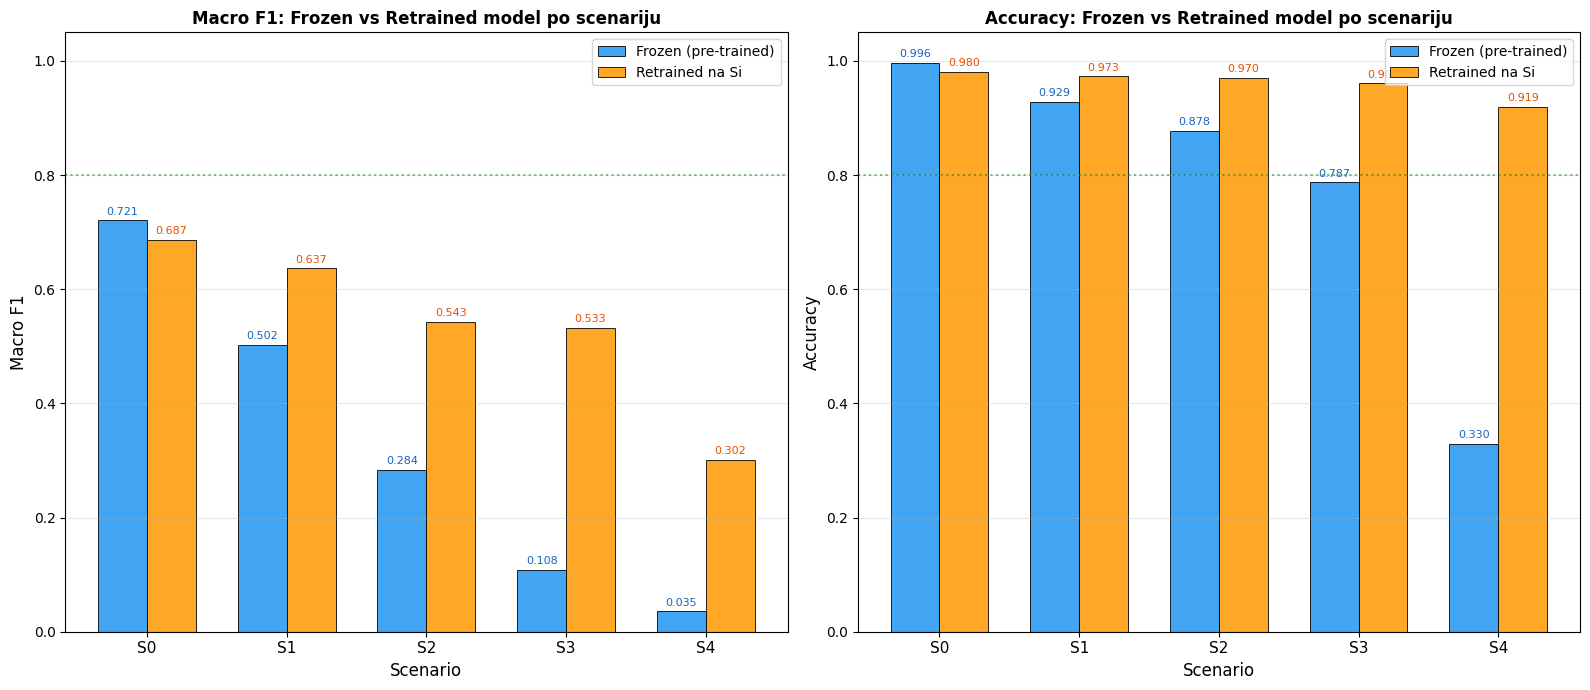

Sačuvano: grafR1_frozen_vs_retrained.png


In [10]:
scenarios_list = list(SCENARIOS.keys())
x = np.arange(len(scenarios_list))
width = 0.35

frozen_f1_vals   = [frozen_results[s]['macro_f1']    for s in scenarios_list]
retrained_f1_vals = [retrained_results[s]['macro_f1'] for s in scenarios_list]
frozen_acc_vals  = [frozen_results[s]['accuracy']    for s in scenarios_list]
retrained_acc_vals = [retrained_results[s]['accuracy'] for s in scenarios_list]

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, frozen_vals, retrained_vals, ylabel, title in [
    (axes[0], frozen_f1_vals,  retrained_f1_vals,  'Macro F1',
     'Macro F1: Frozen vs Retrained model po scenariju'),
    (axes[1], frozen_acc_vals, retrained_acc_vals, 'Accuracy',
     'Accuracy: Frozen vs Retrained model po scenariju'),
]:
    bars1 = ax.bar(x - width/2, frozen_vals,    width, label='Frozen (pre-trained)',
                   color='#2196F3', edgecolor='black', linewidth=0.7, alpha=0.85)
    bars2 = ax.bar(x + width/2, retrained_vals, width, label='Retrained na Si',
                   color='#FF9800', edgecolor='black', linewidth=0.7, alpha=0.85)
    
    ax.set_xlabel('Scenario', fontsize=12)
    ax.set_ylabel(ylabel, fontsize=12)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(scenarios_list, fontsize=11)
    ax.legend(fontsize=10)
    ax.set_ylim(0, 1.05)
    ax.grid(axis='y', alpha=0.3)
    ax.axhline(y=0.8, color='green', linestyle=':', alpha=0.5, label='Operativni prag (0.8 Acc)')
    
    for bar, v in zip(bars1, frozen_vals):
        ax.text(bar.get_x()+bar.get_width()/2, v+0.01, f'{v:.3f}',
               ha='center', fontsize=8, color='#1565C0')
    for bar, v in zip(bars2, retrained_vals):
        ax.text(bar.get_x()+bar.get_width()/2, v+0.01, f'{v:.3f}',
               ha='center', fontsize=8, color='#E65100')

plt.tight_layout()
plt.savefig('grafR1_frozen_vs_retrained.png', dpi=150, bbox_inches='tight')
plt.show()
print("Sačuvano: grafR1_frozen_vs_retrained.png")

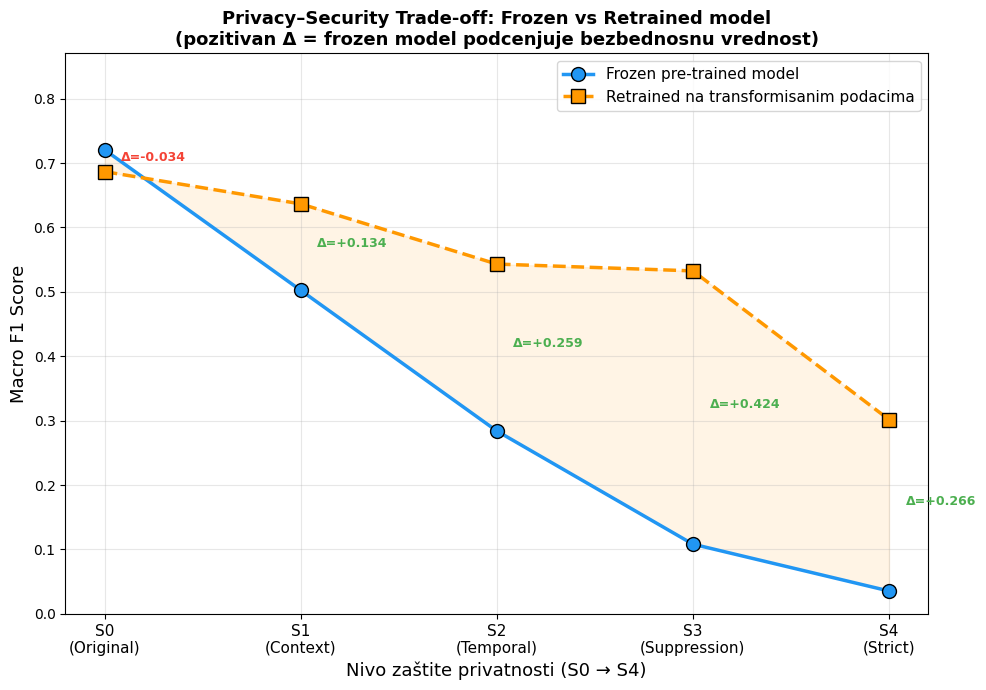

Sačuvano: grafR2_tradeoff_frozen_vs_retrained.png


In [11]:
# Graf R2: Trade-off kriva — frozen vs retrained
privacy_levels = [1, 2, 3, 4, 5]  # S0=1 ... S4=5

fig, ax = plt.subplots(figsize=(10, 7))

ax.plot(privacy_levels, frozen_f1_vals, 'o-',
        color='#2196F3', linewidth=2.5, markersize=10,
        markeredgecolor='black', label='Frozen pre-trained model', zorder=3)

ax.plot(privacy_levels, retrained_f1_vals, 's--',
        color='#FF9800', linewidth=2.5, markersize=10,
        markeredgecolor='black', label='Retrained na transformisanim podacima', zorder=3)

# Označi deltu za svaki scenario
for i, (x_pos, fr, rt, s) in enumerate(zip(privacy_levels, frozen_f1_vals,
                                             retrained_f1_vals, scenarios_list)):
    delta = rt - fr
    mid_y = (fr + rt) / 2
    color = '#4CAF50' if delta > 0 else '#F44336'
    ax.annotate(f'Δ={delta:+.3f}', (x_pos, mid_y),
               xytext=(12, 0), textcoords='offset points',
               fontsize=9, color=color, fontweight='bold')

ax.set_xlabel('Nivo zaštite privatnosti (S0 → S4)', fontsize=13)
ax.set_ylabel('Macro F1 Score', fontsize=13)
ax.set_title('Privacy–Security Trade-off: Frozen vs Retrained model\n'
             '(pozitivan Δ = frozen model podcenjuje bezbednosnu vrednost)',
             fontsize=13, fontweight='bold')
ax.set_xticks(privacy_levels)
ax.set_xticklabels(['S0\n(Original)', 'S1\n(Context)', 'S2\n(Temporal)',
                     'S3\n(Suppression)', 'S4\n(Strict)'], fontsize=11)
ax.legend(fontsize=11)
ax.set_ylim(0, max(max(frozen_f1_vals), max(retrained_f1_vals)) + 0.15)
ax.grid(True, alpha=0.3)
ax.fill_between(privacy_levels, frozen_f1_vals, retrained_f1_vals,
                alpha=0.1, color='#FF9800',
                label='Zona poboljšanja retrainingom')

plt.tight_layout()
plt.savefig('grafR2_tradeoff_frozen_vs_retrained.png', dpi=150, bbox_inches='tight')
plt.show()
print("Sačuvano: grafR2_tradeoff_frozen_vs_retrained.png")

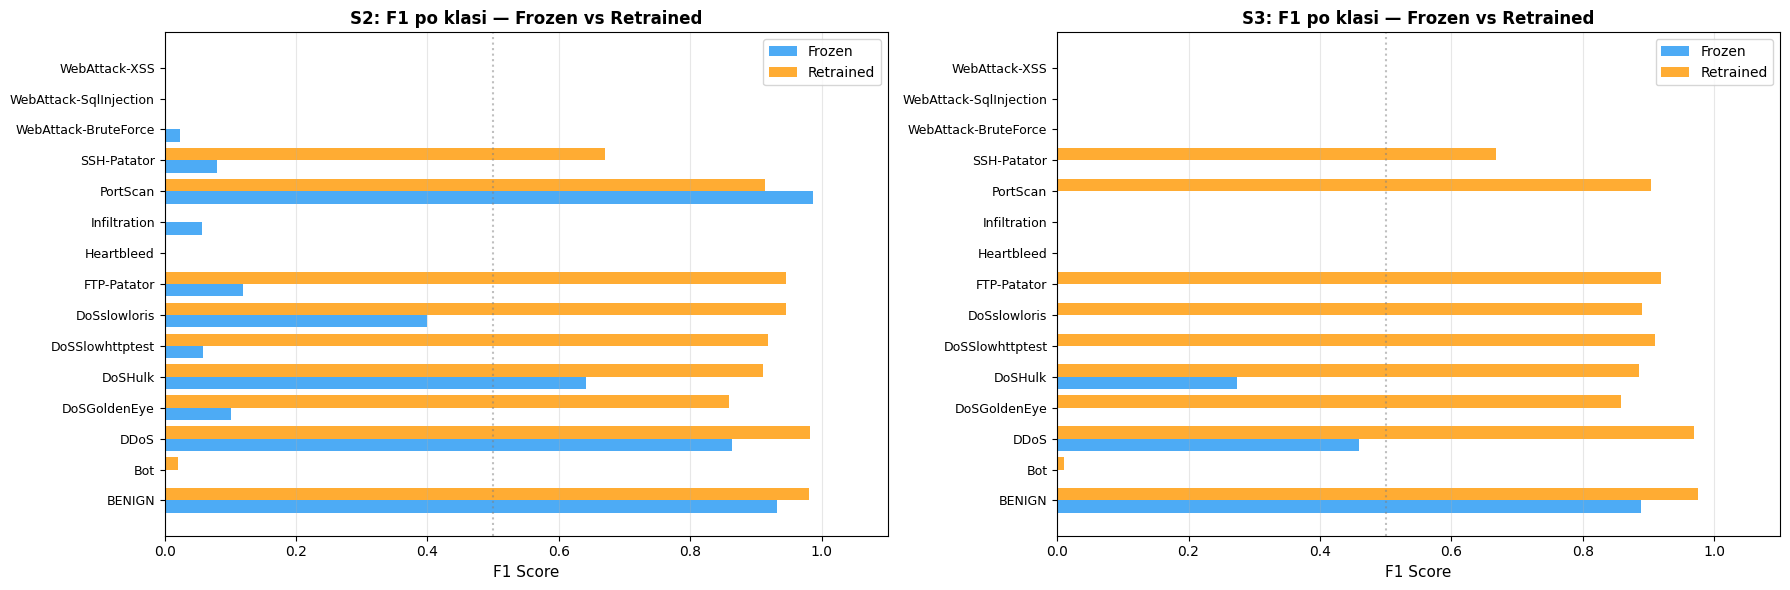

Sačuvano: grafR3_per_class_frozen_vs_retrained.png


In [12]:
# Graf R3: F1 po klasi napada — frozen vs retrained za S2 i S3
# (najinteresantniji scenariji za poređenje)

def get_per_class_f1(res_dict, scenario):
    report = res_dict[scenario]['report']
    return [report.get(cls, {}).get('f1-score', 0.0) for cls in CLASS_NAMES_CLEAN]

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

for ax, s_name in [(axes[0], 'S2'), (axes[1], 'S3')]:
    f1_frozen    = get_per_class_f1(frozen_results,    s_name)
    f1_retrained = get_per_class_f1(retrained_results, s_name)
    
    x_pos = np.arange(len(CLASS_NAMES_CLEAN))
    ax.barh(x_pos - 0.2, f1_frozen,    0.4, label='Frozen',    color='#2196F3', alpha=0.8)
    ax.barh(x_pos + 0.2, f1_retrained, 0.4, label='Retrained', color='#FF9800', alpha=0.8)
    ax.set_yticks(x_pos)
    ax.set_yticklabels(CLASS_NAMES_CLEAN, fontsize=9)
    ax.set_xlabel('F1 Score', fontsize=11)
    ax.set_title(f'{s_name}: F1 po klasi — Frozen vs Retrained', fontsize=12, fontweight='bold')
    ax.legend(fontsize=10)
    ax.set_xlim(0, 1.1)
    ax.grid(axis='x', alpha=0.3)
    ax.axvline(x=0.5, color='gray', linestyle=':', alpha=0.5)

plt.tight_layout()
plt.savefig('grafR3_per_class_frozen_vs_retrained.png', dpi=150, bbox_inches='tight')
plt.show()
print("Sačuvano: grafR3_per_class_frozen_vs_retrained.png")

## 7. Experiment P — Numerical privacy metrics
 
This complements the qualitative WP29 test (singling-out, linkability, inference)
with measurable, quantitative indicators per scenario.
 
### Metrics:
1. **Normalized Shannon entropy** — how diverse the values in the feature group are (higher = more information retained; *but* for privacy: lower = less uniqueness)
2. **Uniqueness score** — share of unique rows in the high-risk feature subspace (singling-out proxy)
3. **k-Anonymity proxy** — average equivalence class size (higher k = better privacy)
4. **Reconstruction risk** — how well the original DestinationPort can be predicted from the bucket value (linkability proxy)

In [13]:
# ─── Definicija rizičnih feature-a za svaki scenario ─────────────────────────
# Biramo reprezentativne feature-e visokog rizika iz svakog scenarija

HIGH_RISK_FEATURES = [
    'DestinationPort',
    'FlowIATMean', 'FlowIATStd',
    'FwdHeaderLength', 'BwdHeaderLength',
    'SYNFlagCount', 'RSTFlagCount',
    'Init_Win_bytes_forward', 'Init_Win_bytes_backward',
    'min_seg_size_forward'
]

# Filtriraj na one koji postoje u datasetu
HIGH_RISK_PRESENT = [f for f in HIGH_RISK_FEATURES if f in X_test_orig.columns]
print(f"Rizični feature-i prisutni u datasetu: {HIGH_RISK_PRESENT}")

Rizični feature-i prisutni u datasetu: ['DestinationPort', 'FlowIATMean', 'FlowIATStd', 'FwdHeaderLength', 'BwdHeaderLength', 'SYNFlagCount', 'RSTFlagCount', 'Init_Win_bytes_forward', 'Init_Win_bytes_backward', 'min_seg_size_forward']


In [14]:
def normalized_entropy(series):
    """
    Shannon entropy normalizovana na [0, 1].
    H = 1.0 → maksimalna raznolikost (svaka vrednost jednako česta)
    H = 0.0 → sve vrednosti iste (nulovanje)
    """
    counts = series.value_counts(normalize=True)
    if len(counts) <= 1:
        return 0.0
    h = -np.sum(counts * np.log2(counts + 1e-10))
    h_max = np.log2(len(counts))
    return float(h / h_max) if h_max > 0 else 0.0


def uniqueness_score(df_subset, n_sample=50_000):
    """
    Udeo jedinstvenih redova u prostoru datih feature-a.
    Visoka jedinstvenost → visok singling-out rizik.
    Koristimo sample za efikasnost.
    """
    sample = df_subset.sample(min(n_sample, len(df_subset)), random_state=42)
    # Diskretiziraj kontinualne kolone na 50 binova za poređenje
    discretized = pd.DataFrame()
    for col in sample.columns:
        if sample[col].nunique() > 100:
            discretized[col] = pd.cut(sample[col], bins=50, labels=False)
        else:
            discretized[col] = sample[col]
    n_unique = len(discretized.drop_duplicates())
    return n_unique / len(discretized)


def k_anonymity_proxy(df_subset, n_sample=50_000):
    """
    Minimalna i prosečna veličina ekvivalentnih klasa.
    Veće k = bolji privatnosti; k=1 znači da je zapis jedinstven.
    """
    sample = df_subset.sample(min(n_sample, len(df_subset)), random_state=42)
    discretized = pd.DataFrame()
    for col in sample.columns:
        if sample[col].nunique() > 100:
            discretized[col] = pd.cut(sample[col], bins=50, labels=False)
        else:
            discretized[col] = sample[col]
    group_sizes = discretized.groupby(list(discretized.columns)).size()
    return {
        'k_min':  int(group_sizes.min()),
        'k_mean': float(group_sizes.mean()),
        'k_median': float(group_sizes.median())
    }


def reconstruction_risk_port(X_transformed):
    """
    Koliko dobro se može rekonstruisati bucket DestinationPort klasa
    iz ostalih feature-a (tj. koliko je S1 bucket dovoljno informativan
    da linkuje zapis nazad na tip servisa).
    
    Interpretacija: visok rizik = bucket vrednost ne skriva dovoljno
    Meri se entropy bucket distribucije unutar svakog tipa napada.
    Niža entropy = više predvidivo = veći rizik.
    """
    if 'DestinationPort' not in X_transformed.columns:
        return None
    
    # Uzmi uzorak za brzinu
    sample_idx = np.random.choice(len(X_transformed), min(100_000, len(X_transformed)),
                                  replace=False)
    port_vals = X_transformed.iloc[sample_idx]['DestinationPort']
    true_classes = y_true[sample_idx]
    
    # Za svaku klasu: koliko je distribucija porta uniformna?
    risk_per_class = {}
    for cls_idx, cls_name in enumerate(CLASS_NAMES_CLEAN):
        mask = true_classes == cls_idx
        if mask.sum() < 5:
            continue
        h = normalized_entropy(port_vals[mask])
        risk_per_class[cls_name] = round(1.0 - h, 4)  # 1 - entropy = risk
    
    return risk_per_class


print("Funkcije za metrike privatnosti definisane.")

Funkcije za metrike privatnosti definisane.


In [15]:
# ─── Računanje metrika za sve scenarije ──────────────────────────────────────
# Napomena: ovo može trajati 5–10 minuta zbog k-anonymity izračunavanja

privacy_metrics = {}

print("Računanje numeričkih metrika privatnosti...\n")

for s_name, transform_fn in SCENARIOS.items():
    print(f"  Scenario {s_name}...", end=" ")
    X_t = transform_fn(X_test_orig)
    
    # Uzmemo samo rizične feature-e koji postoje i nisu sve nule
    risk_cols = [c for c in HIGH_RISK_PRESENT if X_t[c].nunique() > 0]
    X_risk = X_t[risk_cols] if risk_cols else X_t[HIGH_RISK_PRESENT[:3]]
    
    # 1. Entropy po svakom feature-u rizične grupe
    entropies = {col: normalized_entropy(X_t[col]) for col in HIGH_RISK_PRESENT
                 if col in X_t.columns}
    mean_entropy = np.mean(list(entropies.values()))
    
    # 2. Uniqueness score
    uniq = uniqueness_score(X_risk)
    
    # 3. k-Anonymity proxy
    k_stats = k_anonymity_proxy(X_risk)
    
    # 4. Reconstruction risk (samo za port, relevantno za S0/S1)
    recon_risk = reconstruction_risk_port(X_t)
    avg_recon  = np.mean(list(recon_risk.values())) if recon_risk else None
    
    privacy_metrics[s_name] = {
        'mean_entropy':      round(mean_entropy, 4),
        'entropies':         entropies,
        'uniqueness':        round(uniq, 4),
        'k_min':             k_stats['k_min'],
        'k_mean':            round(k_stats['k_mean'], 1),
        'k_median':          round(k_stats['k_median'], 1),
        'recon_risk_avg':    round(avg_recon, 4) if avg_recon else None,
        'recon_risk_detail': recon_risk,
    }
    
    recon_str = f"{avg_recon:.3f}" if avg_recon else "N/A"
    print(f"entropy={mean_entropy:.3f}, uniqueness={uniq:.3f}, k_min={k_stats['k_min']}, recon_risk={recon_str}")

print("\nMetrike izračunate.")

Računanje numeričkih metrika privatnosti...

  Scenario S0... entropy=0.399, uniqueness=0.046, k_min=1, recon_risk=0.843
  Scenario S1... entropy=0.363, uniqueness=0.024, k_min=1, recon_risk=1.000
  Scenario S2... entropy=0.217, uniqueness=0.009, k_min=1, recon_risk=1.000
  Scenario S3... entropy=0.000, uniqueness=0.000, k_min=50000, recon_risk=1.000
  Scenario S4... entropy=0.000, uniqueness=0.000, k_min=50000, recon_risk=1.000

Metrike izračunate.


In [16]:
# ─── Tabelarni prikaz metrika privatnosti ─────────────────────────────────────
pm_rows = []
for s_name in SCENARIOS.keys():
    pm = privacy_metrics[s_name]
    pm_rows.append({
        'Scenario':           s_name,
        'Mean Entropy':       pm['mean_entropy'],   # 0=nulovan, 1=max raznolikost
        'Uniqueness':         pm['uniqueness'],     # visoko=loše za privatnost
        'k_min':              pm['k_min'],          # visoko=dobro za privatnost
        'k_mean':             pm['k_mean'],
        'Recon. Risk (Port)': pm['recon_risk_avg'] if pm['recon_risk_avg'] else '-',
    })

pm_df = pd.DataFrame(pm_rows)

print("\n" + "="*80)
print("TABELA P1 — NUMERIČKE METRIKE PRIVATNOSTI PO SCENARIJU")
print("Interpretacija:")
print("  Mean Entropy:    veća = više info sačuvano; niža = bolji privacy")
print("  Uniqueness:      viša = veći singling-out rizik; niža = bolja privatnost")
print("  k_min:           veće = veća anonimna klasa; k=1 = jedinstven zapis")
print("  Recon. Risk:     veći = bucket ne skriva servisni tip dovoljno")
print("="*80)
print(pm_df.to_string(index=False))


TABELA P1 — NUMERIČKE METRIKE PRIVATNOSTI PO SCENARIJU
Interpretacija:
  Mean Entropy:    veća = više info sačuvano; niža = bolji privacy
  Uniqueness:      viša = veći singling-out rizik; niža = bolja privatnost
  k_min:           veće = veća anonimna klasa; k=1 = jedinstven zapis
  Recon. Risk:     veći = bucket ne skriva servisni tip dovoljno
Scenario  Mean Entropy  Uniqueness  k_min  k_mean  Recon. Risk (Port)
      S0        0.3993      0.0462      1    21.6              0.8431
      S1        0.3632      0.0238      1    41.9              1.0000
      S2        0.2173      0.0087      1   115.2              1.0000
      S3        0.0000      0.0000  50000 50000.0              1.0000
      S4        0.0000      0.0000  50000 50000.0              1.0000


In [17]:
# ─── Kombinovana tabela: Privacy metrike + Security metrike ──────────────────
combined_rows = []
for s_name in SCENARIOS.keys():
    pm  = privacy_metrics[s_name]
    fr  = frozen_results[s_name]
    rt  = retrained_results[s_name]
    combined_rows.append({
        'Scenario':        s_name,
        # Privacy
        'Entropy':         pm['mean_entropy'],
        'Uniqueness':      pm['uniqueness'],
        'k_min':           pm['k_min'],
        # Security — frozen
        'Frozen Acc':      round(fr['accuracy'],  4),
        'Frozen F1':       round(fr['macro_f1'],  4),
        # Security — retrained
        'Retrained Acc':   round(rt['accuracy'],  4),
        'Retrained F1':    round(rt['macro_f1'],  4),
    })

combined_df = pd.DataFrame(combined_rows)

print("\n" + "="*100)
print("TABELA P2 — KOMPLETNO POREĐENJE: PRIVACY + SECURITY (FROZEN + RETRAINED)")
print("="*100)
print(combined_df.to_string(index=False))


TABELA P2 — KOMPLETNO POREĐENJE: PRIVACY + SECURITY (FROZEN + RETRAINED)
Scenario  Entropy  Uniqueness  k_min  Frozen Acc  Frozen F1  Retrained Acc  Retrained F1
      S0   0.3993      0.0462      1      0.9962     0.7206         0.9805        0.6867
      S1   0.3632      0.0238      1      0.9288     0.5024         0.9727        0.6366
      S2   0.2173      0.0087      1      0.8777     0.2840         0.9697        0.5431
      S3   0.0000      0.0000  50000      0.7873     0.1082         0.9605        0.5325
      S4   0.0000      0.0000  50000      0.3296     0.0355         0.9190        0.3016


## 8. Visualization of privacy metrics

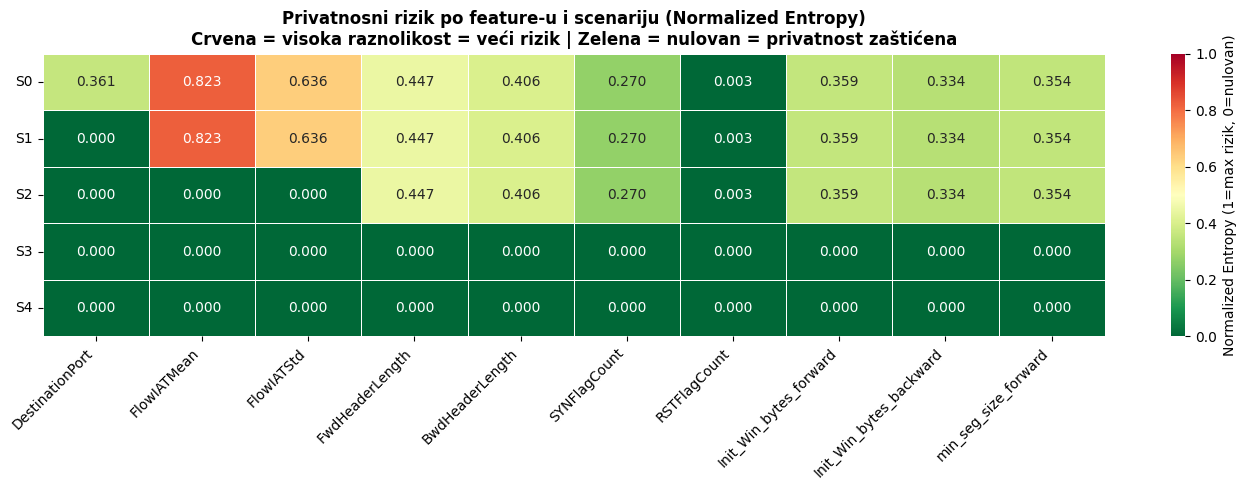

Sačuvano: grafP1_entropy_heatmap.png


In [18]:
# Graf P1: Entropy heatmap po feature-u i scenariju
entropy_data = {}
for s_name, transform_fn in SCENARIOS.items():
    X_t = transform_fn(X_test_orig)
    entropy_data[s_name] = {col: normalized_entropy(X_t[col])
                            for col in HIGH_RISK_PRESENT if col in X_t.columns}

entropy_df = pd.DataFrame(entropy_data).T

fig, ax = plt.subplots(figsize=(14, 5))
sns.heatmap(entropy_df, ax=ax, cmap='RdYlGn_r',  # crveno=visoka entropy=veći rizik
            vmin=0, vmax=1, annot=True, fmt='.3f',
            linewidths=0.4, cbar_kws={'label': 'Normalized Entropy (1=max rizik, 0=nulovan)'})
ax.set_title('Privatnosni rizik po feature-u i scenariju (Normalized Entropy)\n'
             'Crvena = visoka raznolikost = veći rizik | Zelena = nulovan = privatnost zaštićena',
             fontsize=12, fontweight='bold')
ax.set_yticklabels(list(SCENARIOS.keys()), rotation=0)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
plt.tight_layout()
plt.savefig('grafP1_entropy_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
print("Sačuvano: grafP1_entropy_heatmap.png")

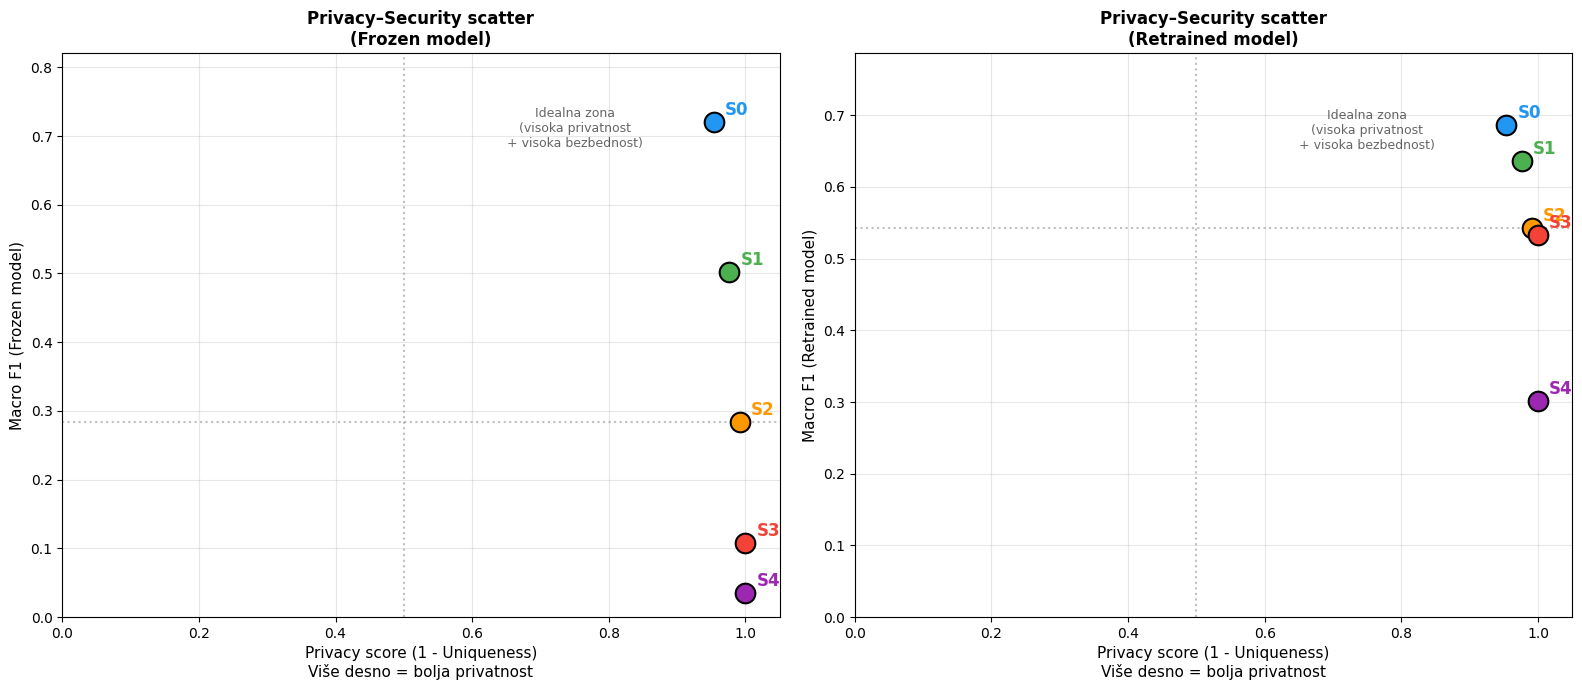

Sačuvano: grafP2_privacy_security_scatter.png


In [19]:
# Graf P2: Privacy vs Security scatter plot
# X-osa: privacy score (niža uniqueness = bolja privatnost → prikazujemo 1-uniqueness)
# Y-osa: security (MacroF1 retrained modela)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

colors_s = ['#2196F3', '#4CAF50', '#FF9800', '#F44336', '#9C27B0']

for ax, sec_vals, title, ylabel in [
    (axes[0],
     [frozen_results[s]['macro_f1'] for s in scenarios_list],
     'Privacy–Security scatter\n(Frozen model)',
     'Macro F1 (Frozen model)'),
    (axes[1],
     [retrained_results[s]['macro_f1'] for s in scenarios_list],
     'Privacy–Security scatter\n(Retrained model)',
     'Macro F1 (Retrained model)'),
]:
    privacy_x = [1 - privacy_metrics[s]['uniqueness'] for s in scenarios_list]
    
    for i, (px, sy, s, c) in enumerate(zip(privacy_x, sec_vals, scenarios_list, colors_s)):
        ax.scatter(px, sy, color=c, s=200, zorder=3, edgecolors='black', linewidth=1.5)
        ax.annotate(s, (px, sy), textcoords='offset points',
                   xytext=(8, 5), fontsize=12, fontweight='bold', color=c)
    
    # Pareto linija (okvirna)
    ax.set_xlabel('Privacy score (1 - Uniqueness)\nViše desno = bolja privatnost', fontsize=11)
    ax.set_ylabel(ylabel, fontsize=11)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.grid(True, alpha=0.3)
    ax.set_xlim(0, 1.05)
    ax.set_ylim(0, max(sec_vals) + 0.1)
    
    # Kvadranti
    ax.axhline(y=np.median(sec_vals), color='gray', linestyle=':', alpha=0.5)
    ax.axvline(x=0.5, color='gray', linestyle=':', alpha=0.5)
    ax.text(0.75, max(sec_vals)*0.95, 'Idealna zona\n(visoka privatnost\n+ visoka bezbednost)',
           fontsize=9, alpha=0.6, ha='center')

plt.tight_layout()
plt.savefig('grafP2_privacy_security_scatter.png', dpi=150, bbox_inches='tight')
plt.show()
print("Sačuvano: grafP2_privacy_security_scatter.png")

## 9. Final conclusions of Experiment R + P

In [20]:
print("=" * 75)
print("FINALNI ZAKLJUČCI — EKSPERIMENT R (RETRAINING)")
print("=" * 75)

for s_name in scenarios_list:
    fr = frozen_results[s_name]
    rt = retrained_results[s_name]
    d_f1 = rt['macro_f1'] - fr['macro_f1']
    
    if abs(d_f1) < 0.02:
        interp = "transformacija menja dostupnu informaciju (ne samo reprezentaciju)"
    elif d_f1 > 0.02:
        interp = f"frozen model PODCENJUJE bezbednosnu vrednost za +{d_f1:.3f} MacroF1"
    else:
        interp = f"frozen model PRECENJUJE bezbednosnu vrednost za {abs(d_f1):.3f} MacroF1"
    
    print(f"\n{s_name}:")
    print(f"  Frozen F1={fr['macro_f1']:.4f} → Retrained F1={rt['macro_f1']:.4f} (Δ={d_f1:+.4f})")
    print(f"  Interpretacija: {interp}")

print("\n" + "=" * 75)
print("FINALNI ZAKLJUČCI — EKSPERIMENT P (PRIVACY METRIKE)")
print("=" * 75)
print()
print(pm_df.to_string(index=False))
print()
print("Napomena za pisanje rada:")
print("  - Entropy blizu 0 za feature = zapis je praktično nulovan (zaštićen)")
print("  - Uniqueness >> 0 za scenario = singling-out rizik i dalje postoji")
print("  - k_min=1 = postoje jedinstveni zapisi u prostoru rizičnih feature-a")
print("  - Ove metrike su proxy i ne zamenjuju formalni privacy audit")
print("=" * 75)

FINALNI ZAKLJUČCI — EKSPERIMENT R (RETRAINING)

S0:
  Frozen F1=0.7206 → Retrained F1=0.6867 (Δ=-0.0340)
  Interpretacija: frozen model PRECENJUJE bezbednosnu vrednost za 0.034 MacroF1

S1:
  Frozen F1=0.5024 → Retrained F1=0.6366 (Δ=+0.1342)
  Interpretacija: frozen model PODCENJUJE bezbednosnu vrednost za +0.134 MacroF1

S2:
  Frozen F1=0.2840 → Retrained F1=0.5431 (Δ=+0.2591)
  Interpretacija: frozen model PODCENJUJE bezbednosnu vrednost za +0.259 MacroF1

S3:
  Frozen F1=0.1082 → Retrained F1=0.5325 (Δ=+0.4243)
  Interpretacija: frozen model PODCENJUJE bezbednosnu vrednost za +0.424 MacroF1

S4:
  Frozen F1=0.0355 → Retrained F1=0.3016 (Δ=+0.2662)
  Interpretacija: frozen model PODCENJUJE bezbednosnu vrednost za +0.266 MacroF1

FINALNI ZAKLJUČCI — EKSPERIMENT P (PRIVACY METRIKE)

Scenario  Mean Entropy  Uniqueness  k_min  k_mean  Recon. Risk (Port)
      S0        0.3993      0.0462      1    21.6              0.8431
      S1        0.3632      0.0238      1    41.9              1.

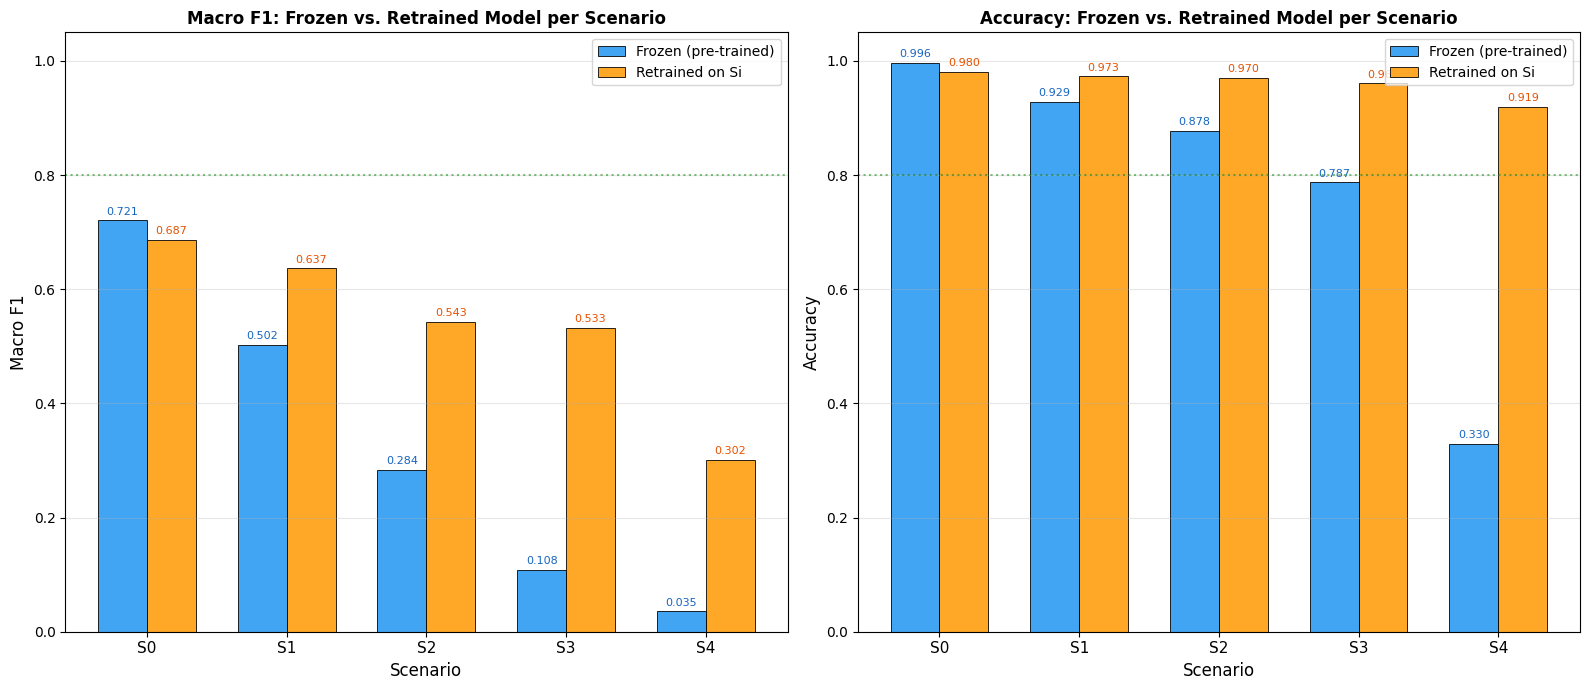

Saved: grafR1_frozen_vs_retrained.png


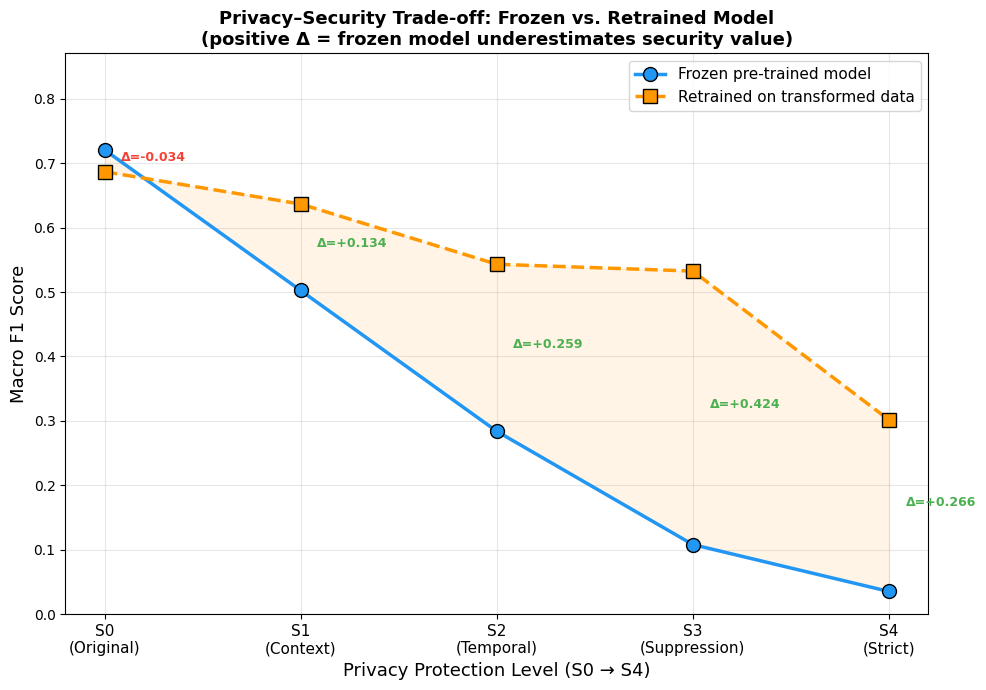

Saved: grafR2_tradeoff_frozen_vs_retrained.png


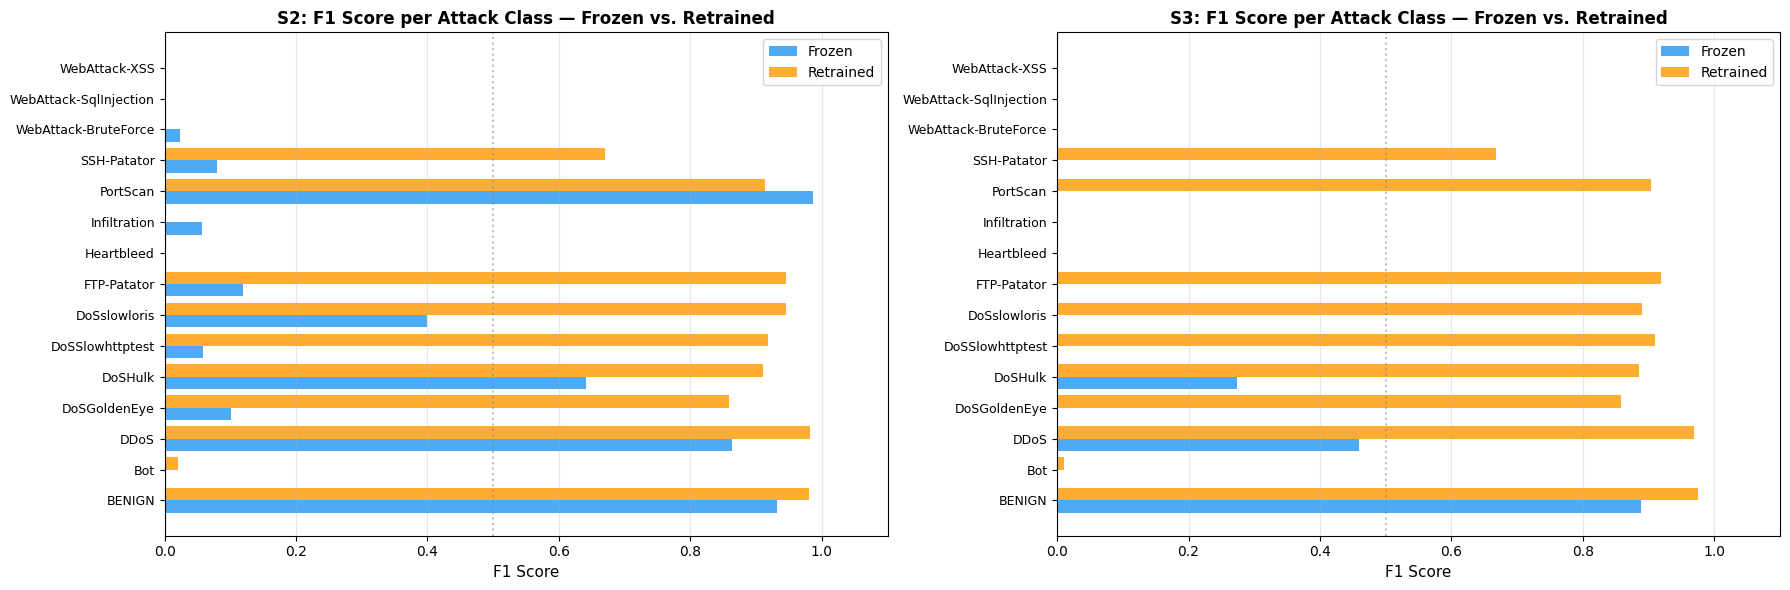

Saved: grafR3_per_class_frozen_vs_retrained.png


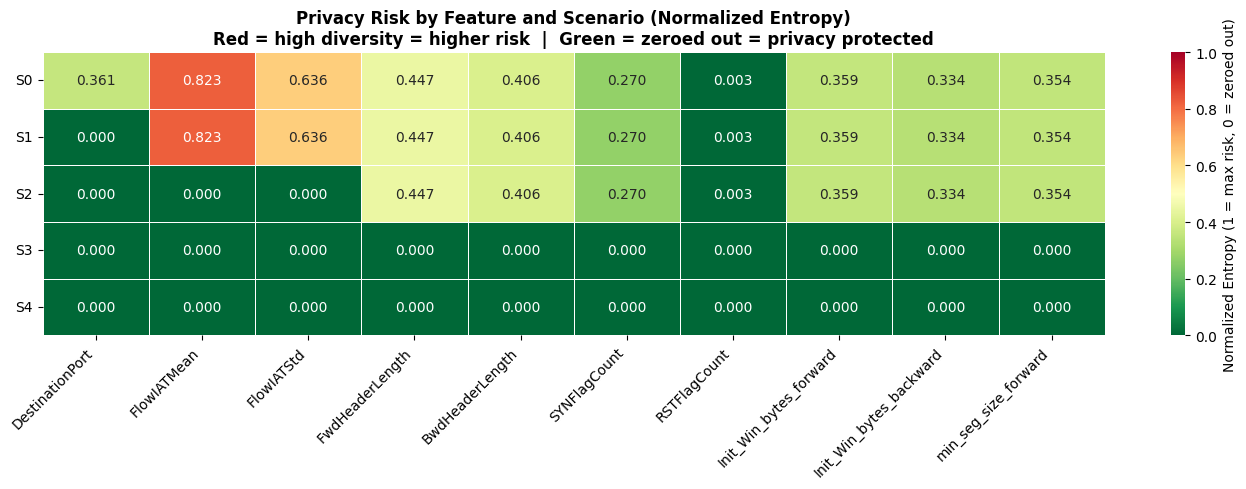

Saved: grafP1_entropy_heatmap.png


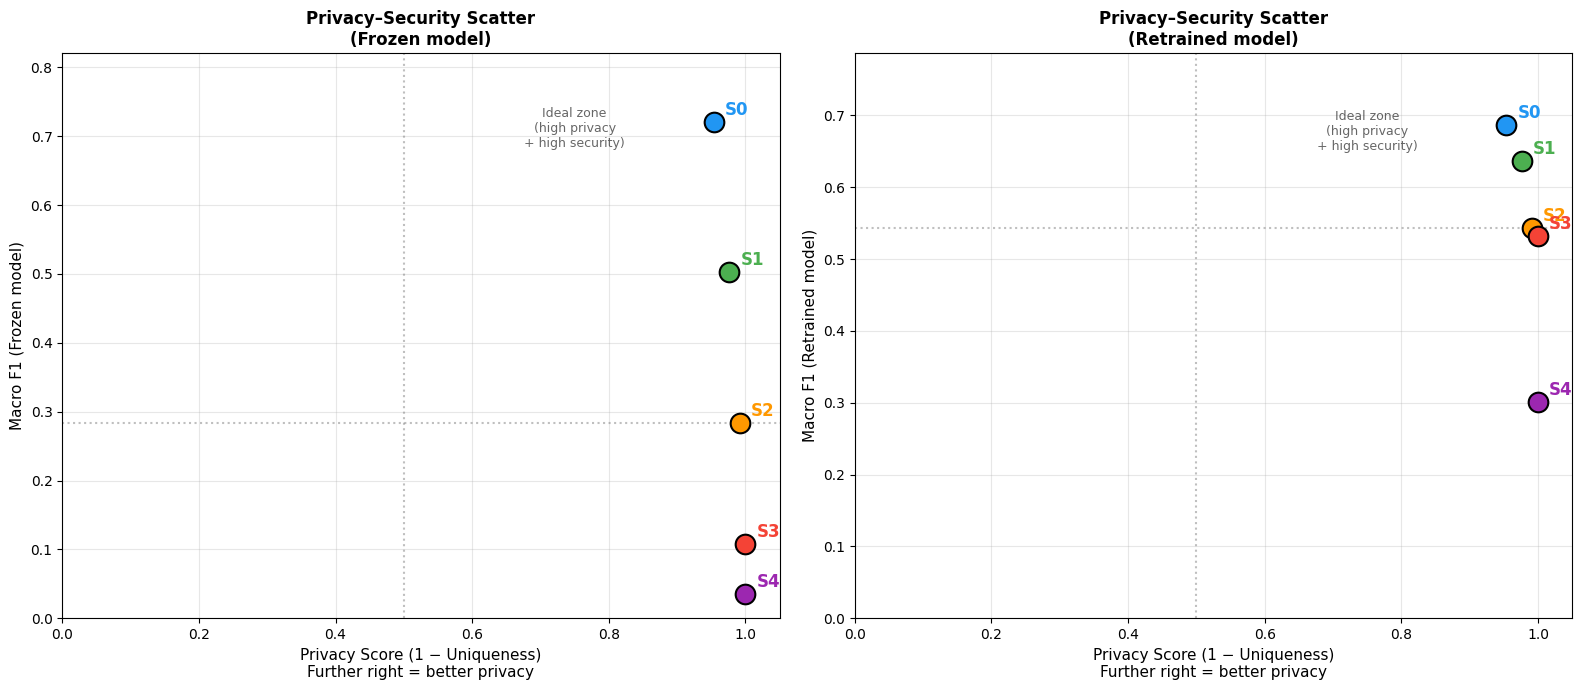

Saved: grafP2_privacy_security_scatter.png

All 5 graphs regenerated with English labels.


In [21]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# ── Graf R1: Frozen vs Retrained — bar chart ─────────────────────────────────
scenarios_list = list(SCENARIOS.keys())
x = np.arange(len(scenarios_list))
width = 0.35

frozen_f1_vals     = [frozen_results[s]['macro_f1']    for s in scenarios_list]
retrained_f1_vals  = [retrained_results[s]['macro_f1'] for s in scenarios_list]
frozen_acc_vals    = [frozen_results[s]['accuracy']    for s in scenarios_list]
retrained_acc_vals = [retrained_results[s]['accuracy'] for s in scenarios_list]

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, frozen_vals, retrained_vals, ylabel, title in [
    (axes[0], frozen_f1_vals, retrained_f1_vals, 'Macro F1',
     'Macro F1: Frozen vs. Retrained Model per Scenario'),
    (axes[1], frozen_acc_vals, retrained_acc_vals, 'Accuracy',
     'Accuracy: Frozen vs. Retrained Model per Scenario'),
]:
    bars1 = ax.bar(x - width/2, frozen_vals,    width, label='Frozen (pre-trained)',
                   color='#2196F3', edgecolor='black', linewidth=0.7, alpha=0.85)
    bars2 = ax.bar(x + width/2, retrained_vals, width, label='Retrained on Si',
                   color='#FF9800', edgecolor='black', linewidth=0.7, alpha=0.85)
    ax.set_xlabel('Scenario', fontsize=12)
    ax.set_ylabel(ylabel, fontsize=12)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(scenarios_list, fontsize=11)
    ax.legend(fontsize=10)
    ax.set_ylim(0, 1.05)
    ax.grid(axis='y', alpha=0.3)
    ax.axhline(y=0.8, color='green', linestyle=':', alpha=0.5, label='Operational threshold (0.8)')
    for bar, v in zip(bars1, frozen_vals):
        ax.text(bar.get_x()+bar.get_width()/2, v+0.01, f'{v:.3f}',
                ha='center', fontsize=8, color='#1565C0')
    for bar, v in zip(bars2, retrained_vals):
        ax.text(bar.get_x()+bar.get_width()/2, v+0.01, f'{v:.3f}',
                ha='center', fontsize=8, color='#E65100')

plt.tight_layout()
plt.savefig('grafR1_frozen_vs_retrained.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: grafR1_frozen_vs_retrained.png")


# ── Graf R2: Trade-off curve ──────────────────────────────────────────────────
privacy_levels = [1, 2, 3, 4, 5]

fig, ax = plt.subplots(figsize=(10, 7))

ax.plot(privacy_levels, frozen_f1_vals, 'o-',
        color='#2196F3', linewidth=2.5, markersize=10,
        markeredgecolor='black', label='Frozen pre-trained model', zorder=3)
ax.plot(privacy_levels, retrained_f1_vals, 's--',
        color='#FF9800', linewidth=2.5, markersize=10,
        markeredgecolor='black', label='Retrained on transformed data', zorder=3)

for x_pos, fr, rt, s in zip(privacy_levels, frozen_f1_vals, retrained_f1_vals, scenarios_list):
    delta = rt - fr
    mid_y = (fr + rt) / 2
    color = '#4CAF50' if delta > 0 else '#F44336'
    ax.annotate(f'Δ={delta:+.3f}', (x_pos, mid_y),
                xytext=(12, 0), textcoords='offset points',
                fontsize=9, color=color, fontweight='bold')

ax.set_xlabel('Privacy Protection Level (S0 → S4)', fontsize=13)
ax.set_ylabel('Macro F1 Score', fontsize=13)
ax.set_title('Privacy–Security Trade-off: Frozen vs. Retrained Model\n'
             '(positive Δ = frozen model underestimates security value)',
             fontsize=13, fontweight='bold')
ax.set_xticks(privacy_levels)
ax.set_xticklabels(['S0\n(Original)', 'S1\n(Context)', 'S2\n(Temporal)',
                    'S3\n(Suppression)', 'S4\n(Strict)'], fontsize=11)
ax.legend(fontsize=11)
ax.set_ylim(0, max(max(frozen_f1_vals), max(retrained_f1_vals)) + 0.15)
ax.grid(True, alpha=0.3)
ax.fill_between(privacy_levels, frozen_f1_vals, retrained_f1_vals,
                alpha=0.1, color='#FF9800')

plt.tight_layout()
plt.savefig('grafR2_tradeoff_frozen_vs_retrained.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: grafR2_tradeoff_frozen_vs_retrained.png")


# ── Graf R3: Per-class F1 for S2 and S3 ──────────────────────────────────────
def get_per_class_f1(res_dict, scenario):
    report = res_dict[scenario]['report']
    return [report.get(cls, {}).get('f1-score', 0.0) for cls in CLASS_NAMES_CLEAN]

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

for ax, s_name in [(axes[0], 'S2'), (axes[1], 'S3')]:
    f1_frozen    = get_per_class_f1(frozen_results,    s_name)
    f1_retrained = get_per_class_f1(retrained_results, s_name)
    x_pos = np.arange(len(CLASS_NAMES_CLEAN))
    ax.barh(x_pos - 0.2, f1_frozen,    0.4, label='Frozen',    color='#2196F3', alpha=0.8)
    ax.barh(x_pos + 0.2, f1_retrained, 0.4, label='Retrained', color='#FF9800', alpha=0.8)
    ax.set_yticks(x_pos)
    ax.set_yticklabels(CLASS_NAMES_CLEAN, fontsize=9)
    ax.set_xlabel('F1 Score', fontsize=11)
    ax.set_title(f'{s_name}: F1 Score per Attack Class — Frozen vs. Retrained',
                 fontsize=12, fontweight='bold')
    ax.legend(fontsize=10)
    ax.set_xlim(0, 1.1)
    ax.grid(axis='x', alpha=0.3)
    ax.axvline(x=0.5, color='gray', linestyle=':', alpha=0.5)

plt.tight_layout()
plt.savefig('grafR3_per_class_frozen_vs_retrained.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: grafR3_per_class_frozen_vs_retrained.png")


# ── Graf P1: Entropy heatmap ──────────────────────────────────────────────────
entropy_data = {}
for s_name, transform_fn in SCENARIOS.items():
    X_t = transform_fn(X_test_orig)
    entropy_data[s_name] = {col: normalized_entropy(X_t[col])
                            for col in HIGH_RISK_PRESENT if col in X_t.columns}

entropy_df = pd.DataFrame(entropy_data).T

fig, ax = plt.subplots(figsize=(14, 5))
sns.heatmap(entropy_df, ax=ax, cmap='RdYlGn_r',
            vmin=0, vmax=1, annot=True, fmt='.3f',
            linewidths=0.4,
            cbar_kws={'label': 'Normalized Entropy (1 = max risk, 0 = zeroed out)'})
ax.set_title('Privacy Risk by Feature and Scenario (Normalized Entropy)\n'
             'Red = high diversity = higher risk  |  Green = zeroed out = privacy protected',
             fontsize=12, fontweight='bold')
ax.set_yticklabels(list(SCENARIOS.keys()), rotation=0)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
plt.tight_layout()
plt.savefig('grafP1_entropy_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: grafP1_entropy_heatmap.png")


# ── Graf P2: Privacy vs Security scatter ─────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
colors_s = ['#2196F3', '#4CAF50', '#FF9800', '#F44336', '#9C27B0']

for ax, sec_vals, title, ylabel in [
    (axes[0],
     [frozen_results[s]['macro_f1'] for s in scenarios_list],
     'Privacy–Security Scatter\n(Frozen model)',
     'Macro F1 (Frozen model)'),
    (axes[1],
     [retrained_results[s]['macro_f1'] for s in scenarios_list],
     'Privacy–Security Scatter\n(Retrained model)',
     'Macro F1 (Retrained model)'),
]:
    privacy_x = [1 - privacy_metrics[s]['uniqueness'] for s in scenarios_list]
    for px, sy, s, c in zip(privacy_x, sec_vals, scenarios_list, colors_s):
        ax.scatter(px, sy, color=c, s=200, zorder=3, edgecolors='black', linewidth=1.5)
        ax.annotate(s, (px, sy), textcoords='offset points',
                    xytext=(8, 5), fontsize=12, fontweight='bold', color=c)
    ax.set_xlabel('Privacy Score (1 − Uniqueness)\nFurther right = better privacy', fontsize=11)
    ax.set_ylabel(ylabel, fontsize=11)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.grid(True, alpha=0.3)
    ax.set_xlim(0, 1.05)
    ax.set_ylim(0, max(sec_vals) + 0.1)
    ax.axhline(y=np.median(sec_vals), color='gray', linestyle=':', alpha=0.5)
    ax.axvline(x=0.5, color='gray', linestyle=':', alpha=0.5)
    ax.text(0.75, max(sec_vals)*0.95,
            'Ideal zone\n(high privacy\n+ high security)',
            fontsize=9, alpha=0.6, ha='center')

plt.tight_layout()
plt.savefig('grafP2_privacy_security_scatter.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: grafP2_privacy_security_scatter.png")

print("\nAll 5 graphs regenerated with English labels.")


In [22]:
import pandas as pd

# Definicija GROUP_OS_FINGERPRINT iz originalnog koda
GROUP_OS_FINGERPRINT = [
    'FwdHeaderLength', 'BwdHeaderLength',
    'SYNFlagCount', 'RSTFlagCount',
    'Init_Win_bytes_forward', 'Init_Win_bytes_backward',
    'min_seg_size_forward'
]

# Korak 1a — Tačna lista kolona koje S3 nulira
print("GROUP_OS_FINGERPRINT (kolone koje S3 nulira):")
for col in GROUP_OS_FINGERPRINT:
    print(f"  {col}")
print(f"\nUkupno kolona u S3: {len(GROUP_OS_FINGERPRINT)}")

# Korak 1b — Da li iste kolone postoje u 2018 datasetu?
print("\nProvera u CIC-IDS-2018 datasetu:")
test_2018 = pd.read_parquet(
    r'C:\Users\AndjelaPC\Documents\ids-anonymization-2018\testset_2018.parquet',
    engine='pyarrow'
)
cols_2018 = [c for c in test_2018.columns if not c.startswith('Label_')]

print(f"\n{'CICIDS2017 naziv':<35} {'Postoji u 2018?':<20} {'2018 naziv'}")
print("-"*80)
for col in GROUP_OS_FINGERPRINT:
    if col in cols_2018:
        print(f"  {col:<33} {'DA':<20} {col}")
    else:
        similar = [c for c in cols_2018 if col.lower().replace('_','') in c.lower().replace('_','')]
        if similar:
            print(f"  {col:<33} {'DRUGACIJI NAZIV':<20} {similar}")
        else:
            print(f"  {col:<33} {'NE POSTOJI':<20} -")

GROUP_OS_FINGERPRINT (kolone koje S3 nulira):
  FwdHeaderLength
  BwdHeaderLength
  SYNFlagCount
  RSTFlagCount
  Init_Win_bytes_forward
  Init_Win_bytes_backward
  min_seg_size_forward

Ukupno kolona u S3: 7

Provera u CIC-IDS-2018 datasetu:

CICIDS2017 naziv                    Postoji u 2018?      2018 naziv
--------------------------------------------------------------------------------
  FwdHeaderLength                   DA                   FwdHeaderLength
  BwdHeaderLength                   DA                   BwdHeaderLength
  SYNFlagCount                      DA                   SYNFlagCount
  RSTFlagCount                      DA                   RSTFlagCount
  Init_Win_bytes_forward            DA                   Init_Win_bytes_forward
  Init_Win_bytes_backward           DA                   Init_Win_bytes_backward
  min_seg_size_forward              DA                   min_seg_size_forward


In [23]:
import numpy as np

# Učitaj test set 2018
X_test_2018 = test_2018[[c for c in test_2018.columns if not c.startswith('Label_')]].copy()

print("Vrednosti pre S3 transformacije u 2018:")
for col in GROUP_OS_FINGERPRINT:
    unique_vals = X_test_2018[col].nunique()
    print(f"  {col:<35} unique vrednosti: {unique_vals}")

# Primeni S3 transformaciju
def zero_out(X, features):
    X2 = X.copy()
    for col in features:
        if col in X2.columns:
            X2[col] = 0
    return X2

def apply_port_bucketing(X):
    X2 = X.copy()
    if 'DestinationPort' in X2.columns:
        X2['DestinationPort'] = X2['DestinationPort'].apply(
            lambda p: 0 if p <= 1023 else (1 if p <= 49151 else 2))
    return X2

def apply_temporal_gen(X, bin_us=10_000):
    GROUP_TEMPORAL = [
        'FlowIATMean', 'FlowIATStd', 'FlowIATMax', 'FlowIATMin',
        'FwdIATTotal', 'FwdIATMean', 'FwdIATStd', 'FwdIATMax', 'FwdIATMin',
        'BwdIATTotal', 'BwdIATMean', 'BwdIATStd', 'BwdIATMax', 'BwdIATMin',
        'ActiveMean', 'ActiveStd', 'ActiveMax', 'ActiveMin',
        'IdleMean', 'IdleStd', 'IdleMax', 'IdleMin'
    ]
    X2 = X.copy()
    for col in GROUP_TEMPORAL:
        if col in X2.columns:
            X2[col] = (X2[col] / bin_us).round() * bin_us
    return X2

def apply_s3(X):
    X2 = apply_temporal_gen(apply_port_bucketing(X), 10_000)
    return zero_out(X2, GROUP_OS_FINGERPRINT)

X_s3_2018 = apply_s3(X_test_2018)

print("\nVrednosti POSLE S3 transformacije u 2018:")
for col in GROUP_OS_FINGERPRINT:
    unique_vals = X_s3_2018[col].nunique()
    non_zero = (X_s3_2018[col] != 0).sum()
    print(f"  {col:<35} unique: {unique_vals}, non-zero: {non_zero}")

Vrednosti pre S3 transformacije u 2018:
  FwdHeaderLength                     unique vrednosti: 2682
  BwdHeaderLength                     unique vrednosti: 3219
  SYNFlagCount                        unique vrednosti: 2
  RSTFlagCount                        unique vrednosti: 2
  Init_Win_bytes_forward              unique vrednosti: 7615
  Init_Win_bytes_backward             unique vrednosti: 8474
  min_seg_size_forward                unique vrednosti: 10

Vrednosti POSLE S3 transformacije u 2018:
  FwdHeaderLength                     unique: 1, non-zero: 0
  BwdHeaderLength                     unique: 1, non-zero: 0
  SYNFlagCount                        unique: 1, non-zero: 0
  RSTFlagCount                        unique: 1, non-zero: 0
  Init_Win_bytes_forward              unique: 1, non-zero: 0
  Init_Win_bytes_backward             unique: 1, non-zero: 0
  min_seg_size_forward                unique: 1, non-zero: 0


In [24]:
HIGH_RISK_FEATURES = [
    'DestinationPort',
    'FlowIATMean', 'FlowIATStd',
    'FwdHeaderLength', 'BwdHeaderLength',
    'SYNFlagCount', 'RSTFlagCount',
    'Init_Win_bytes_forward', 'Init_Win_bytes_backward',
    'min_seg_size_forward'
]

def normalized_entropy(series):
    counts = series.value_counts(normalize=True)
    if len(counts) <= 1:
        return 0.0
    h = -np.sum(counts * np.log2(counts + 1e-10))
    h_max = np.log2(len(counts))
    return float(h / h_max) if h_max > 0 else 0.0

print("Entropija po feature-u za S3 na 2018:")
print(f"\n{'Feature':<35} {'Entropija'}")
print("-"*50)
entropies = {}
for col in HIGH_RISK_FEATURES:
    if col in X_s3_2018.columns:
        e = normalized_entropy(X_s3_2018[col])
        entropies[col] = e
        print(f"  {col:<33} {e:.4f}")

mean_e = np.mean(list(entropies.values()))
print(f"\nMean entropy: {mean_e:.4f}")
print(f"\nObjašnjenje: kolone koje nisu nula su FlowIATMean i FlowIATStd")
print(f"(temporalne — nisu deo GROUP_OS_FINGERPRINT, nego GROUP_TEMPORAL)")

Entropija po feature-u za S3 na 2018:

Feature                             Entropija
--------------------------------------------------
  DestinationPort                   0.8689
  FlowIATMean                       0.4974
  FlowIATStd                        0.4417
  FwdHeaderLength                   0.0000
  BwdHeaderLength                   0.0000
  SYNFlagCount                      0.0000
  RSTFlagCount                      0.0000
  Init_Win_bytes_forward            0.0000
  Init_Win_bytes_backward           0.0000
  min_seg_size_forward              0.0000

Mean entropy: 0.1808

Objašnjenje: kolone koje nisu nula su FlowIATMean i FlowIATStd
(temporalne — nisu deo GROUP_OS_FINGERPRINT, nego GROUP_TEMPORAL)


Učitavam modele...
Računam F1 po klasi...


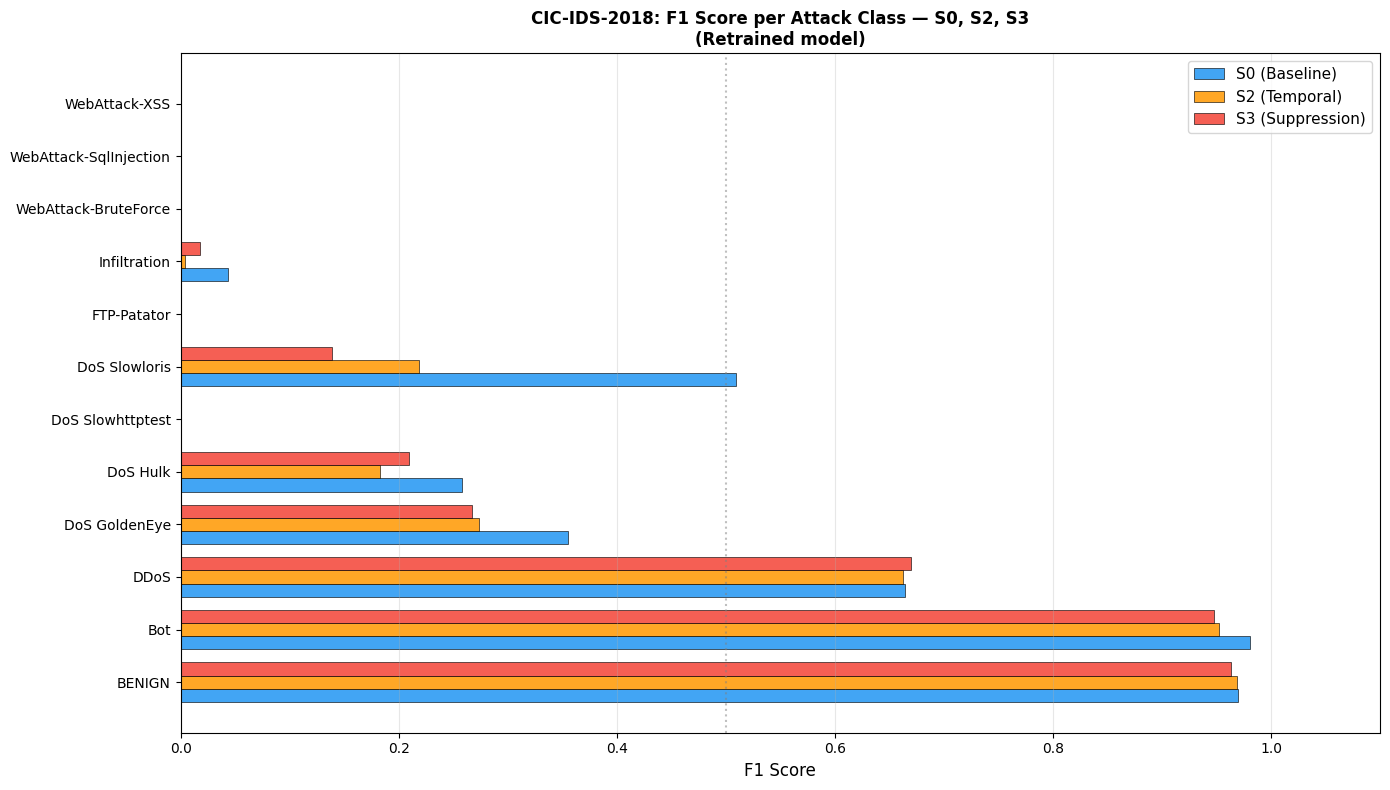

Sačuvano: graf_2018_per_class_S0_S2_S3.png


In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn import metrics

PATH_2018 = r'C:\Users\AndjelaPC\Documents\ids-anonymization-2018'

# Učitaj test set
test_2018 = pd.read_parquet(PATH_2018 + '/testset_2018.parquet', engine='pyarrow').sample(frac=0.2, random_state=42)
label_cols   = [c for c in test_2018.columns if c.startswith('Label_')]
feature_cols = [c for c in test_2018.columns if not c.startswith('Label_')]
X_test_2018  = test_2018[feature_cols].copy()
y_true_2018  = np.argmax(test_2018[label_cols].to_numpy(), axis=1)
CLASS_NAMES_2018 = [c.replace('Label_', '') for c in label_cols]

# Učitaj retrained modele
import tensorflow as tf
from tensorflow import keras

def get_per_class_f1(model, X, y_true, class_names):
    y_pred = np.argmax(model.predict(X.to_numpy(), verbose=0), axis=1)
    classes_present = sorted(set(y_true))
    report = metrics.classification_report(
        y_true, y_pred,
        labels=classes_present,
        target_names=[class_names[i] for i in classes_present],
        output_dict=True, zero_division=0
    )
    return [report.get(cls, {}).get('f1-score', 0.0) for cls in class_names]

# Transformacije
GROUP_OS_FINGERPRINT = ['FwdHeaderLength','BwdHeaderLength','SYNFlagCount','RSTFlagCount',
                        'Init_Win_bytes_forward','Init_Win_bytes_backward','min_seg_size_forward']
GROUP_TEMPORAL = ['FlowIATMean','FlowIATStd','FlowIATMax','FlowIATMin',
                  'FwdIATTotal','FwdIATMean','FwdIATStd','FwdIATMax','FwdIATMin',
                  'BwdIATTotal','BwdIATMean','BwdIATStd','BwdIATMax','BwdIATMin',
                  'ActiveMean','ActiveStd','ActiveMax','ActiveMin',
                  'IdleMean','IdleStd','IdleMax','IdleMin']
GROUP_STRICT_KEEP = ['FlowDuration','TotalFwdPackets','TotalBackwardPackets',
                     'FlowBytes/s','FlowPackets/s','AveragePacketSize',
                     'Down/UpRatio','FwdPackets/s','BwdPackets/s']

def apply_s0(X): return X.copy()
def apply_s2(X):
    X2 = X.copy()
    if 'DestinationPort' in X2.columns:
        X2['DestinationPort'] = X2['DestinationPort'].apply(lambda p: 0 if p<=1023 else (1 if p<=49151 else 2))
    for col in GROUP_TEMPORAL:
        if col in X2.columns:
            X2[col] = (X2[col]/10_000).round()*10_000
    return X2
def apply_s3(X):
    X2 = apply_s2(X)
    for col in GROUP_OS_FINGERPRINT:
        if col in X2.columns:
            X2[col] = 0
    return X2

print("Učitavam modele...")
model_s0 = keras.models.load_model(PATH_2018 + '/retrained_2018_S0.keras')
model_s2 = keras.models.load_model(PATH_2018 + '/retrained_2018_S2.keras')
model_s3 = keras.models.load_model(PATH_2018 + '/retrained_2018_S3.keras')

print("Računam F1 po klasi...")
f1_s0 = get_per_class_f1(model_s0, apply_s0(X_test_2018), y_true_2018, CLASS_NAMES_2018)
f1_s2 = get_per_class_f1(model_s2, apply_s2(X_test_2018), y_true_2018, CLASS_NAMES_2018)
f1_s3 = get_per_class_f1(model_s3, apply_s3(X_test_2018), y_true_2018, CLASS_NAMES_2018)

# Graf
fig, ax = plt.subplots(figsize=(14, 8))
x = np.arange(len(CLASS_NAMES_2018))
width = 0.25

ax.barh(x - width, f1_s0, width, label='S0 (Baseline)', color='#2196F3', alpha=0.85, edgecolor='black', linewidth=0.5)
ax.barh(x,         f1_s2, width, label='S2 (Temporal)', color='#FF9800', alpha=0.85, edgecolor='black', linewidth=0.5)
ax.barh(x + width, f1_s3, width, label='S3 (Suppression)', color='#F44336', alpha=0.85, edgecolor='black', linewidth=0.5)

ax.set_yticks(x)
ax.set_yticklabels(CLASS_NAMES_2018, fontsize=10)
ax.set_xlabel('F1 Score', fontsize=12)
ax.set_title('CIC-IDS-2018: F1 Score per Attack Class — S0, S2, S3\n(Retrained model)',
             fontsize=12, fontweight='bold')
ax.legend(fontsize=11)
ax.set_xlim(0, 1.1)
ax.grid(axis='x', alpha=0.3)
ax.axvline(x=0.5, color='gray', linestyle=':', alpha=0.5)

plt.tight_layout()
plt.savefig(PATH_2018 + '/graf_2018_per_class_S0_S2_S3.png', dpi=150, bbox_inches='tight')
plt.show()
print("Sačuvano: graf_2018_per_class_S0_S2_S3.png")

In [26]:
import pandas as pd

per_class_2018 = pd.DataFrame({
    'S0': [round(v, 3) for v in f1_s0],
    'S2': [round(v, 3) for v in f1_s2],
    'S3': [round(v, 3) for v in f1_s3],
}, index=CLASS_NAMES_2018)

# Sortiraj po S0 F1 opadajuće, radi preglednosti
per_class_2018 = per_class_2018.sort_values('S0', ascending=False)

print(per_class_2018)
per_class_2018.to_csv('cic2018_per_class_f1.csv')

                           S0     S2     S3
Bot                     0.981  0.953  0.948
BENIGN                  0.970  0.969  0.964
DDoS                    0.664  0.663  0.669
DoS Slowloris           0.510  0.218  0.139
DoS GoldenEye           0.355  0.274  0.267
DoS Hulk                0.259  0.183  0.209
Infiltration            0.044  0.004  0.018
DoS Slowhttptest        0.000  0.000  0.000
FTP-Patator             0.000  0.000  0.000
WebAttack-BruteForce    0.000  0.000  0.000
WebAttack-SqlInjection  0.000  0.000  0.000
WebAttack-XSS           0.000  0.000  0.000


In [27]:
import pandas as pd

# --- TEST distribucija (imamo direktno iz test_2018) ---
label_cols_test = [c for c in test_2018.columns if c.startswith('Label_')]
test_counts = test_2018[label_cols_test].sum().sort_values(ascending=False)
test_counts.index = [c.replace('Label_', '') for c in test_counts.index]

test_dist = pd.DataFrame({
    'Test set': test_counts.astype(int),
    'Test [%]': (test_counts / test_counts.sum() * 100).round(2)
})
print("=== TEST distribucija (CIC-IDS-2018) ===")
print(test_dist)
test_dist.to_csv('cic2018_test_distribution.csv')

# --- Provera odakle učitati TRAIN 2018 ---
print("\n=== PATH_2018 ===")
print(PATH_2018)
print("\n=== cols_2018 (prvih 20) ===")
print(cols_2018[:20] if hasattr(cols_2018, '__getitem__') else cols_2018)

=== TEST distribucija (CIC-IDS-2018) ===
                        Test set  Test [%]
BENIGN                    422551     90.89
DDoS                       22921      4.93
DoS Hulk                    5855      1.26
Bot                         5789      1.25
Infiltration                5675      1.22
DoS GoldenEye               1693      0.36
DoS Slowloris                399      0.09
WebAttack-BruteForce          29      0.01
WebAttack-XSS                  8      0.00
WebAttack-SqlInjection         6      0.00
DoS Slowhttptest               2      0.00
FTP-Patator                    1      0.00

=== PATH_2018 ===
C:\Users\AndjelaPC\Documents\ids-anonymization-2018

=== cols_2018 (prvih 20) ===
['DestinationPort', 'FlowDuration', 'TotalFwdPackets', 'TotalBackwardPackets', 'TotalLengthofFwdPackets', 'TotalLengthofBwdPackets', 'FwdPacketLengthMax', 'FwdPacketLengthMin', 'FwdPacketLengthMean', 'FwdPacketLengthStd', 'BwdPacketLengthMax', 'BwdPacketLengthMin', 'BwdPacketLengthMean', 'BwdPacket

In [28]:
import gc
gc.collect()

import pyarrow.parquet as pq

# Pročitaj SAMO imena kolona iz fajla (bez učitavanja podataka)
schema = pq.read_schema(PATH_2018 + '/trainset_2018.parquet')
label_cols_tr = [c for c in schema.names if c.startswith('Label_')]
print("Label kolone:", label_cols_tr)

# Učitaj SAMO label kolone (ne feature kolone) — drasti čno manje memorije
train_labels_only = pd.read_parquet(
    PATH_2018 + '/trainset_2018.parquet',
    engine='pyarrow',
    columns=label_cols_tr
)
print("Ukupno redova u train fajlu:", len(train_labels_only))

Label kolone: ['Label_BENIGN', 'Label_Bot', 'Label_DDoS', 'Label_DoS GoldenEye', 'Label_DoS Hulk', 'Label_DoS Slowhttptest', 'Label_DoS Slowloris', 'Label_FTP-Patator', 'Label_Infiltration', 'Label_WebAttack-BruteForce', 'Label_WebAttack-SqlInjection', 'Label_WebAttack-XSS']
Ukupno redova u train fajlu: 9298583


In [29]:
# Uzmi isti 10% sample sa istim seed-om kao u radu
train_sample = train_labels_only.sample(frac=0.1, random_state=42)

train_counts = train_sample.sum().sort_values(ascending=False)
train_counts.index = [c.replace('Label_', '') for c in train_counts.index]

train_dist = pd.DataFrame({
    'Training set': train_counts.astype(int),
    'Train [%]': (train_counts / train_counts.sum() * 100).round(2)
})
print("=== TRAIN distribucija (CIC-IDS-2018) ===")
print(train_dist)
print("\nUkupno train sample:", int(train_counts.sum()))
train_dist.to_csv('cic2018_train_distribution.csv')

# Oslobodi memoriju
del train_labels_only, train_sample
gc.collect()

=== TRAIN distribucija (CIC-IDS-2018) ===
                        Training set  Train [%]
BENIGN                        845111      90.89
DDoS                           45935       4.94
DoS Hulk                       11805       1.27
Bot                            11455       1.23
Infiltration                   11336       1.22
DoS GoldenEye                   3324       0.36
DoS Slowloris                    802       0.09
WebAttack-BruteForce              62       0.01
WebAttack-XSS                     20       0.00
WebAttack-SqlInjection             5       0.00
DoS Slowhttptest                   3       0.00
FTP-Patator                        0       0.00

Ukupno train sample: 929858


0

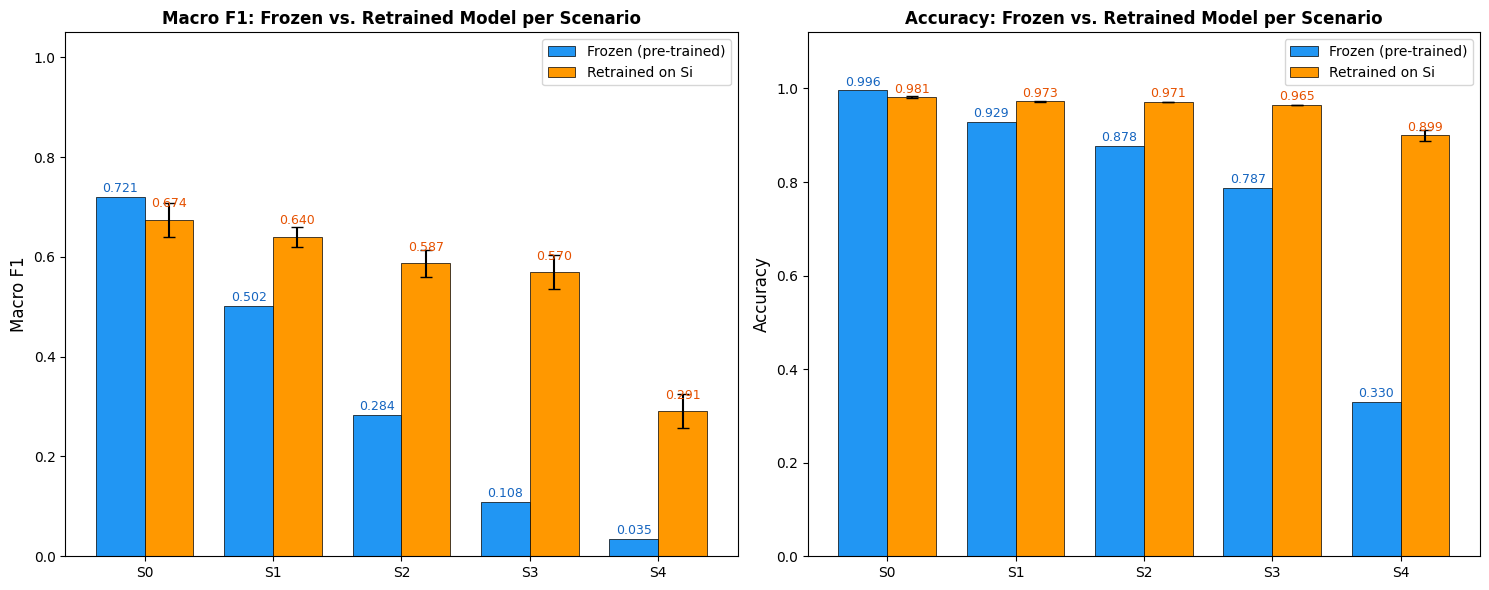

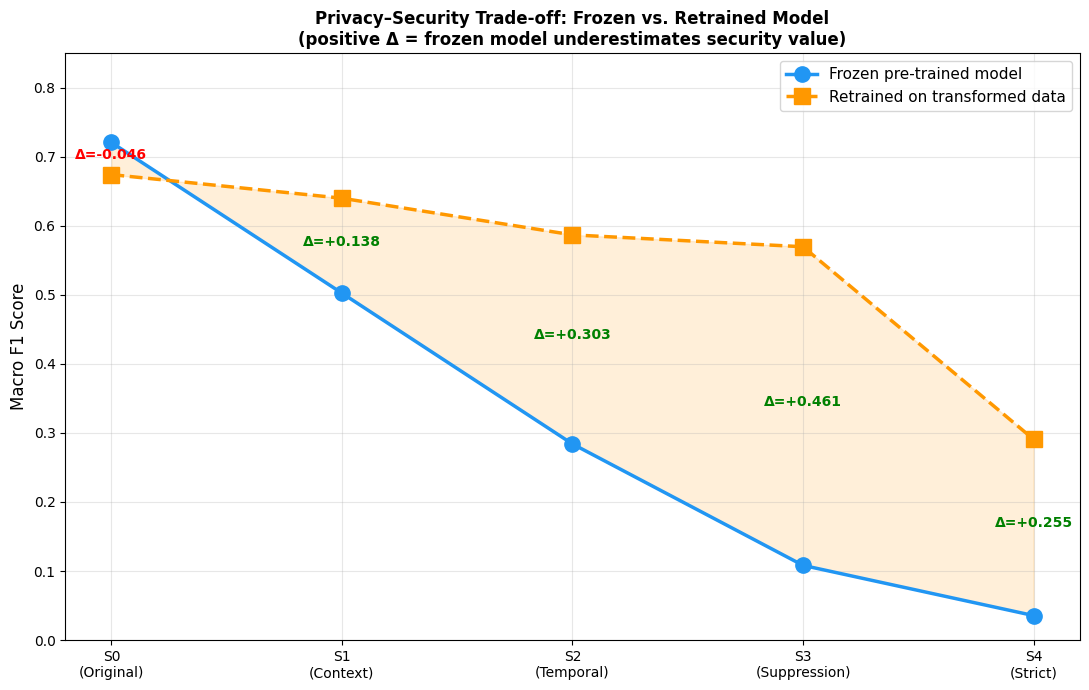

Regenerisano BEZ operational threshold linije:
  grafR1_frozen_vs_retrained_MULTISEED.png
  grafR2_tradeoff_frozen_vs_retrained_MULTISEED.png

Retrained F1 (multi-seed mean): ['0.674', '0.640', '0.587', '0.570', '0.291']


In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Učitaj multi-seed proseke
summary = pd.read_csv('multiseed_summary.csv')  # kolone: scenario, acc_mean, acc_std, f1_mean, f1_std, wf1_mean, wf1_std
summary = summary.set_index('scenario').reindex(['S0','S1','S2','S3','S4'])
scenarios = ['S0','S1','S2','S3','S4']
labels = ['S0\n(Original)','S1\n(Context)','S2\n(Temporal)','S3\n(Suppression)','S4\n(Strict)']

# FROZEN vrednosti (fiksne, iz Tabele 5.1)
frozen_f1  = [0.7206, 0.5024, 0.2840, 0.1082, 0.0355]
frozen_acc = [0.9962, 0.9288, 0.8777, 0.7873, 0.3296]

# RETRAINED mean vrednosti (iz multi-seed)
retr_f1   = summary['f1_mean'].values
retr_f1_std = summary['f1_std'].values
retr_acc  = summary['acc_mean'].values
retr_acc_std = summary['acc_std'].values

# ============ SLIKA 3 (regen): Bar chart Frozen vs Retrained, F1 + Acc ============
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
x = np.arange(len(scenarios)); width = 0.38
b1 = ax1.bar(x - width/2, frozen_f1, width, label='Frozen (pre-trained)', color='#2196F3', edgecolor='black', linewidth=0.5)
b2 = ax1.bar(x + width/2, retr_f1, width, yerr=retr_f1_std, capsize=4, label='Retrained on Si', color='#FF9800', edgecolor='black', linewidth=0.5)
ax1.set_ylabel('Macro F1', fontsize=12); ax1.set_title('Macro F1: Frozen vs. Retrained Model per Scenario', fontsize=12, fontweight='bold')
ax1.set_xticks(x); ax1.set_xticklabels(scenarios); ax1.legend(fontsize=10); ax1.set_ylim(0, 1.05)
for bar, v in zip(b1, frozen_f1): ax1.text(bar.get_x()+bar.get_width()/2, v+0.01, f'{v:.3f}', ha='center', fontsize=9, color='#1565C0')
for bar, v in zip(b2, retr_f1): ax1.text(bar.get_x()+bar.get_width()/2, v+0.025, f'{v:.3f}', ha='center', fontsize=9, color='#E65100')

b3 = ax2.bar(x - width/2, frozen_acc, width, label='Frozen (pre-trained)', color='#2196F3', edgecolor='black', linewidth=0.5)
b4 = ax2.bar(x + width/2, retr_acc, width, yerr=retr_acc_std, capsize=4, label='Retrained on Si', color='#FF9800', edgecolor='black', linewidth=0.5)
ax2.set_ylabel('Accuracy', fontsize=12); ax2.set_title('Accuracy: Frozen vs. Retrained Model per Scenario', fontsize=12, fontweight='bold')
ax2.set_xticks(x); ax2.set_xticklabels(scenarios); ax2.legend(fontsize=10); ax2.set_ylim(0, 1.12)
for bar, v in zip(b3, frozen_acc): ax2.text(bar.get_x()+bar.get_width()/2, v+0.01, f'{v:.3f}', ha='center', fontsize=9, color='#1565C0')
for bar, v in zip(b4, retr_acc): ax2.text(bar.get_x()+bar.get_width()/2, v+0.01, f'{v:.3f}', ha='center', fontsize=9, color='#E65100')

plt.tight_layout()
plt.savefig('grafR1_frozen_vs_retrained_MULTISEED.png', dpi=150, bbox_inches='tight')
plt.show()

# ============ SLIKA 4 (regen): Trade-off sa Δ ============
fig, ax = plt.subplots(figsize=(11, 7))
ax.plot(range(5), frozen_f1, 'o-', color='#2196F3', lw=2.5, markersize=11, label='Frozen pre-trained model')
ax.plot(range(5), retr_f1, 's--', color='#FF9800', lw=2.5, markersize=11, label='Retrained on transformed data')
ax.fill_between(range(5), frozen_f1, retr_f1, alpha=0.15, color='#FF9800')
for i in range(5):
    d = retr_f1[i] - frozen_f1[i]
    col = 'green' if d >= 0 else 'red'
    ax.annotate(f'Δ={d:+.3f}', (i, (frozen_f1[i]+retr_f1[i])/2), fontsize=10, fontweight='bold', color=col, ha='center')
ax.set_xticks(range(5)); ax.set_xticklabels(labels, fontsize=10)
ax.set_ylabel('Macro F1 Score', fontsize=12)
ax.set_title('Privacy–Security Trade-off: Frozen vs. Retrained Model\n(positive Δ = frozen model underestimates security value)', fontsize=12, fontweight='bold')
ax.legend(fontsize=11, loc='upper right'); ax.grid(alpha=0.3); ax.set_ylim(0, 0.85)
plt.tight_layout()
plt.savefig('grafR2_tradeoff_frozen_vs_retrained_MULTISEED.png', dpi=150, bbox_inches='tight')
plt.show()

print("Regenerisano BEZ operational threshold linije:")
print("  grafR1_frozen_vs_retrained_MULTISEED.png")
print("  grafR2_tradeoff_frozen_vs_retrained_MULTISEED.png")
print("\nRetrained F1 (multi-seed mean):", [f'{v:.3f}' for v in retr_f1])

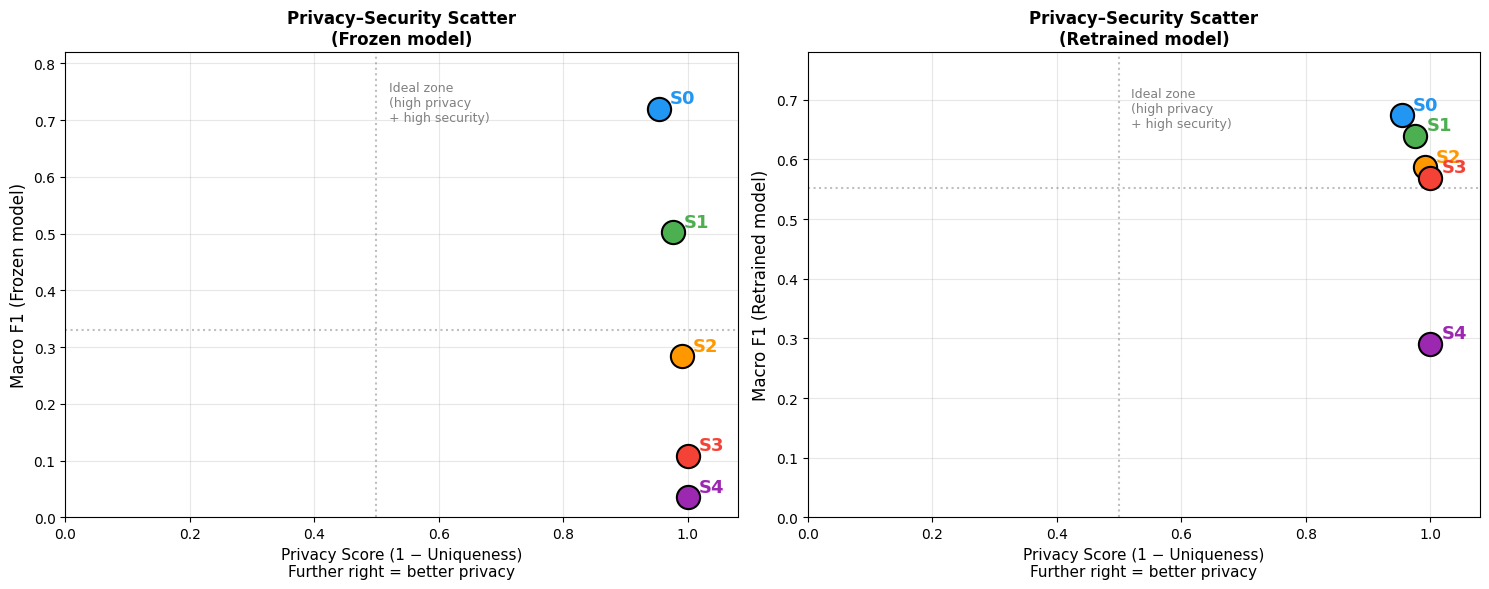

Regenerisano: grafP2_privacy_security_scatter_MULTISEED.png
Retrained F1: ['0.674', '0.640', '0.587', '0.570', '0.291']


In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

summary = pd.read_csv('multiseed_summary.csv').set_index('scenario').reindex(['S0','S1','S2','S3','S4'])

scenarios = ['S0','S1','S2','S3','S4']
colors = ['#2196F3','#4CAF50','#FF9800','#F44336','#9C27B0']

frozen_f1 = [0.7206, 0.5024, 0.2840, 0.1082, 0.0355]
retr_f1   = summary['f1_mean'].values
uniqueness = [0.046, 0.024, 0.009, 0.000, 0.000]           # iz Tabele 5.6
privacy_score = [1 - u for u in uniqueness]                 # veći = bolja privatnost

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

for ax, f1_vals, title in [(ax1, frozen_f1, 'Frozen model'), (ax2, retr_f1, 'Retrained model')]:
    for i, s in enumerate(scenarios):
        ax.scatter(privacy_score[i], f1_vals[i], s=280, color=colors[i], edgecolor='black', linewidth=1.5, zorder=3)
        ax.annotate(s, (privacy_score[i], f1_vals[i]), fontsize=13, fontweight='bold',
                    color=colors[i], xytext=(8, 4), textcoords='offset points')
    ax.axvline(0.5, color='gray', ls=':', alpha=0.5)
    ymid = np.mean(f1_vals)
    ax.axhline(ymid, color='gray', ls=':', alpha=0.5)
    ax.text(0.52, max(f1_vals)*0.97, 'Ideal zone\n(high privacy\n+ high security)', fontsize=9, color='gray')
    ax.set_xlabel('Privacy Score (1 − Uniqueness)\nFurther right = better privacy', fontsize=11)
    ax.set_ylabel(f'Macro F1 ({title})', fontsize=12)
    ax.set_title(f'Privacy–Security Scatter\n({title})', fontsize=12, fontweight='bold')
    ax.set_xlim(0, 1.08); ax.grid(alpha=0.3)

ax1.set_ylim(0, 0.82)
ax2.set_ylim(0, 0.78)

plt.tight_layout()
plt.savefig('grafP2_privacy_security_scatter_MULTISEED.png', dpi=150, bbox_inches='tight')
plt.show()
print("Regenerisano: grafP2_privacy_security_scatter_MULTISEED.png")
print("Retrained F1:", [f'{v:.3f}' for v in retr_f1])

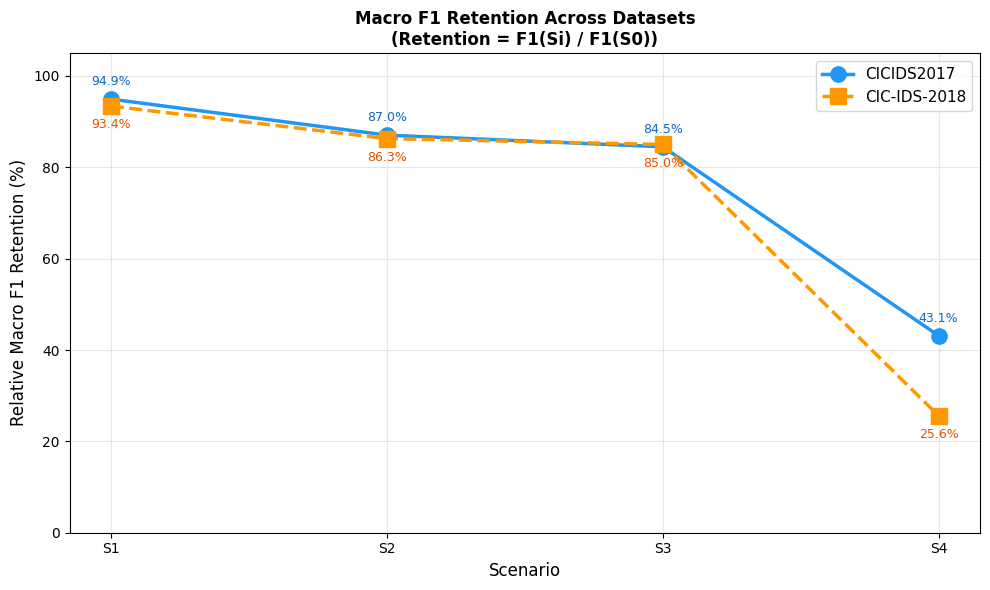

Regenerisano: graf_tradeoff_2017_vs_2018_MULTISEED.png


In [32]:
import matplotlib.pyplot as plt

scenarios = ['S1','S2','S3','S4']
retention_2017 = [94.93, 87.05, 84.50, 43.14]   # nove multi-seed vrednosti, Tabela 5.8
retention_2018 = [93.40, 86.30, 85.00, 25.60]

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(scenarios, retention_2017, 'o-', color='#2196F3', lw=2.5, markersize=11, label='CICIDS2017')
ax.plot(scenarios, retention_2018, 's--', color='#FF9800', lw=2.5, markersize=11, label='CIC-IDS-2018')
for i, s in enumerate(scenarios):
    ax.annotate(f'{retention_2017[i]:.1f}%', (i, retention_2017[i]), textcoords='offset points',
                xytext=(0, 10), ha='center', fontsize=9, color='#1565C0')
    ax.annotate(f'{retention_2018[i]:.1f}%', (i, retention_2018[i]), textcoords='offset points',
                xytext=(0, -16), ha='center', fontsize=9, color='#E65100')
ax.set_xlabel('Scenario', fontsize=12)
ax.set_ylabel('Relative Macro F1 Retention (%)', fontsize=12)
ax.set_title('Macro F1 Retention Across Datasets\n(Retention = F1(Si) / F1(S0))', fontsize=12, fontweight='bold')
ax.legend(fontsize=11); ax.grid(alpha=0.3); ax.set_ylim(0, 105)
plt.tight_layout()
plt.savefig('graf_tradeoff_2017_vs_2018_MULTISEED.png', dpi=150, bbox_inches='tight')
plt.show()
print("Regenerisano: graf_tradeoff_2017_vs_2018_MULTISEED.png")

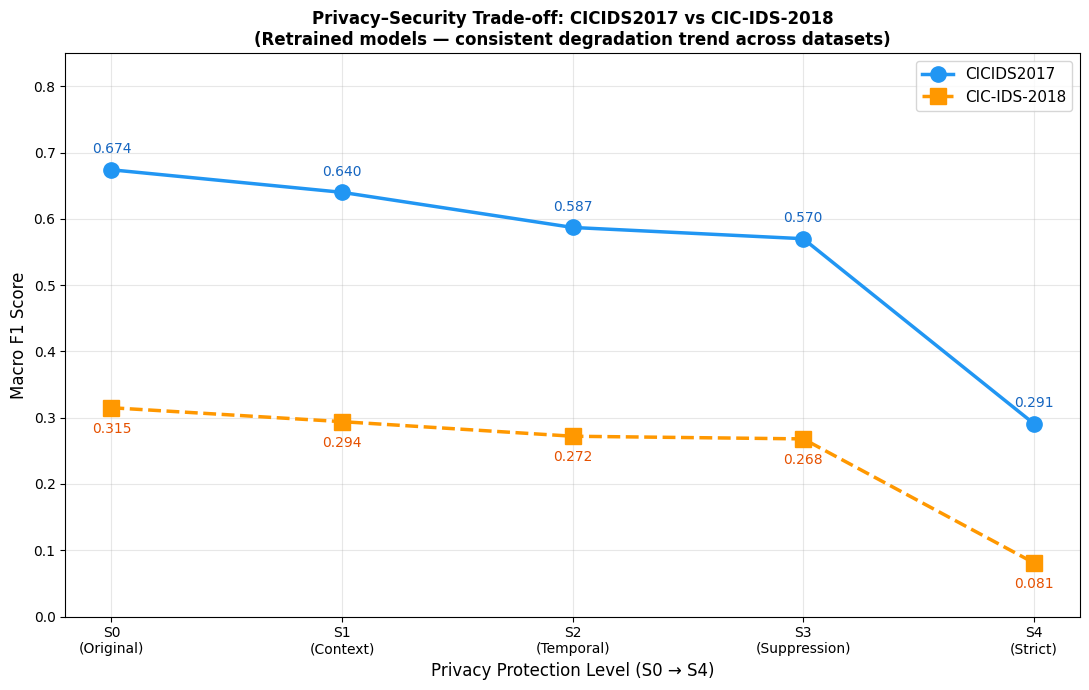

Regenerisano. CICIDS2017 F1: ['0.674', '0.640', '0.587', '0.570', '0.291']


In [33]:
import matplotlib.pyplot as plt
import pandas as pd

summary = pd.read_csv('multiseed_summary.csv').set_index('scenario').reindex(['S0','S1','S2','S3','S4'])

labels = ['S0\n(Original)','S1\n(Context)','S2\n(Temporal)','S3\n(Suppression)','S4\n(Strict)']
f1_2017 = summary['f1_mean'].round(3).values          # multi-seed mean: 0.674, 0.640, 0.587, 0.570, 0.291
f1_2018 = [0.315, 0.294, 0.272, 0.268, 0.081]         # single-run 2018 (Tabela 5.7)

fig, ax = plt.subplots(figsize=(11, 7))
ax.plot(range(5), f1_2017, 'o-', color='#2196F3', lw=2.5, markersize=11, label='CICIDS2017')
ax.plot(range(5), f1_2018, 's--', color='#FF9800', lw=2.5, markersize=11, label='CIC-IDS-2018')

for i in range(5):
    ax.annotate(f'{f1_2017[i]:.3f}', (i, f1_2017[i]), textcoords='offset points',
                xytext=(0, 12), ha='center', fontsize=10, color='#1565C0')
    ax.annotate(f'{f1_2018[i]:.3f}', (i, f1_2018[i]), textcoords='offset points',
                xytext=(0, -18), ha='center', fontsize=10, color='#E65100')

ax.set_xticks(range(5)); ax.set_xticklabels(labels, fontsize=10)
ax.set_xlabel('Privacy Protection Level (S0 → S4)', fontsize=12)
ax.set_ylabel('Macro F1 Score', fontsize=12)
ax.set_title('Privacy–Security Trade-off: CICIDS2017 vs CIC-IDS-2018\n(Retrained models — consistent degradation trend across datasets)',
             fontsize=12, fontweight='bold')
ax.legend(fontsize=11); ax.grid(alpha=0.3); ax.set_ylim(0, 0.85)
plt.tight_layout()
plt.savefig('graf_tradeoff_2017_vs_2018_MULTISEED.png', dpi=150, bbox_inches='tight')
plt.show()
print("Regenerisano. CICIDS2017 F1:", [f'{v:.3f}' for v in f1_2017])

In [34]:
import pandas as pd
import numpy as np
from scipy import stats

df = pd.read_csv('multiseed_results.csv')

# Svi susedni parovi scenarija
pairs = [('S0','S1'), ('S1','S2'), ('S2','S3'), ('S3','S4')]

print(f"{'Pair':<10} {'mean_A':>8} {'mean_B':>8} {'Δ':>8} {'t-stat':>8} {'p-value':>10} {'95% CI':>20} {'Robust?':>8}")
print("-" * 85)

for a, b in pairs:
    vals_a = df[df['scenario'] == a]['macro_f1'].values
    vals_b = df[df['scenario'] == b]['macro_f1'].values
    
    t_stat, p_val = stats.ttest_ind(vals_a, vals_b, equal_var=False)  # Welch t-test
    
    diff = vals_a.mean() - vals_b.mean()
    se = np.sqrt(vals_a.var(ddof=1)/len(vals_a) + vals_b.var(ddof=1)/len(vals_b))
    ci_low = diff - 2.306 * se   # t-kritična za df≈4 (konzervativno), 95%
    ci_high = diff + 2.306 * se
    
    robust = "YES" if p_val < 0.05 else "NO"
    
    print(f"{a}-{b:<7} {vals_a.mean():>8.4f} {vals_b.mean():>8.4f} {diff:>8.4f} {t_stat:>8.3f} {p_val:>10.4f} [{ci_low:>7.4f}, {ci_high:>7.4f}]  {robust:>5}")

print("\nInterpretacija: p < 0.05 = statistički značajna razlika (95% nivo poverenja)")

Pair         mean_A   mean_B        Δ   t-stat    p-value               95% CI  Robust?
-------------------------------------------------------------------------------------
S0-S1        0.6741   0.6399   0.0342    1.913     0.1015 [-0.0070,  0.0754]     NO
S1-S2        0.6399   0.5868   0.0531    3.501     0.0094 [ 0.0181,  0.0881]    YES
S2-S3        0.5868   0.5696   0.0172    0.868     0.4120 [-0.0285,  0.0628]     NO
S3-S4        0.5696   0.2908   0.2788   12.787     0.0000 [ 0.2285,  0.3291]    YES

Interpretacija: p < 0.05 = statistički značajna razlika (95% nivo poverenja)


In [35]:
from scipy.stats import entropy as scipy_entropy
print("\n=== Entropija po feature-ima za S3 na CIC-IDS-2018 ===")

# S3 kolone koje se nuliraju
s3_cols = ['FwdHeaderLength', 'BwdHeaderLength', 'SYNFlagCount', 
           'RSTFlagCount', 'Init_Win_bytes_forward', 
           'Init_Win_bytes_backward', 'min_seg_size_forward']

# High-risk feature-i koje treba proveriti
check_features = [
    'DestinationPort',   # ispravno ime
    'FlowIATMean',       # ispravno ime  
    'FlowIATStd',        # ispravno ime
    'FwdHeaderLength', 'BwdHeaderLength', 
    'SYNFlagCount', 'RSTFlagCount',
    'Init_Win_bytes_forward', 'Init_Win_bytes_backward',
    'min_seg_size_forward'
]
X_test_s3 = X_s3_2018
for feat in check_features:
    if feat in X_test_s3.columns:
        vals = X_test_s3[feat].value_counts(normalize=True)
        ent = scipy_entropy(vals, base=2)
        n_unique = X_test_s3[feat].nunique()
        print(f"{feat}: entropy={ent:.3f}, unique={n_unique}")
    else:
        print(f"NIJE PRONADJENA: {feat}")


=== Entropija po feature-ima za S3 na CIC-IDS-2018 ===
DestinationPort: entropy=1.377, unique=3
FlowIATMean: entropy=6.286, unique=6379
FlowIATStd: entropy=5.399, unique=4783
FwdHeaderLength: entropy=0.000, unique=1
BwdHeaderLength: entropy=0.000, unique=1
SYNFlagCount: entropy=0.000, unique=1
RSTFlagCount: entropy=0.000, unique=1
Init_Win_bytes_forward: entropy=0.000, unique=1
Init_Win_bytes_backward: entropy=0.000, unique=1
min_seg_size_forward: entropy=0.000, unique=1


In [36]:
# # ═══════════════════════════════════════════════════════════════
# # MULTI-SEED EVALUACIJA — 5 scenarija × 5 seedova = 25 treninga
# # ═══════════════════════════════════════════════════════════════

# import os, random, time
# import numpy as np
# import pandas as pd
# import tensorflow as tf
# from tensorflow import keras
# from sklearn import metrics

# SEEDS = [42, 7, 13, 21, 99]
# RESULTS_CSV = 'multiseed_results.csv'

# def set_all_seeds(seed):
#     os.environ['PYTHONHASHSEED'] = str(seed)
#     random.seed(seed)
#     np.random.seed(seed)
#     tf.random.set_seed(seed)
#     keras.utils.set_random_seed(seed)

# # Učitaj već završene kombinacije ako postoje
# if os.path.exists(RESULTS_CSV):
#     done_df = pd.read_csv(RESULTS_CSV)
#     done_set = set(zip(done_df['scenario'], done_df['seed']))
#     all_rows = done_df.to_dict('records')
#     print(f"Nastavljam. Već završeno: {len(done_set)} od {len(SCENARIOS)*len(SEEDS)}")
# else:
#     done_set = set()
#     all_rows = []
#     print("Krećem od nule.")

# y_true = np.argmax(y_test.to_numpy(), axis=1)
# total = len(SCENARIOS) * len(SEEDS)
# counter = len(done_set)
# t_start = time.time()

# for s_name, transform_fn in SCENARIOS.items():
#     X_train_t = transform_fn(X_train_orig)
#     X_test_t  = transform_fn(X_test_orig)

#     for seed in SEEDS:
#         if (s_name, seed) in done_set:
#             continue

#         counter += 1
#         t0 = time.time()
#         print(f"\n[{counter}/{total}] {s_name} seed={seed} ...", flush=True)

#         set_all_seeds(seed)

#         model = keras.Sequential([
#             keras.layers.Input(shape=(X_train_t.shape[1],)),
#             keras.layers.Dense(90, activation='relu'),
#             keras.layers.Dense(50, activation='relu'),
#             keras.layers.Dense(y_train.shape[1], activation='softmax')
#         ])
#         model.compile(
#             optimizer=keras.optimizers.Adam(learning_rate=0.001),
#             loss='categorical_crossentropy',
#             metrics=['accuracy']
#         )

#         print("Počinje trening modela...", flush=True)

#         model.fit(
#             X_train_t.to_numpy(), y_train.to_numpy(),
#             epochs=15,
#              batch_size=2048,
#             validation_split=0.1,
#             callbacks=[keras.callbacks.EarlyStopping(
#                 monitor='val_loss', patience=3,
#                 restore_best_weights=True, verbose=1
#             )],
#             verbose=1
#         )

#         print("Trening završen, radim predikciju...", flush=True)

#         y_pred = np.argmax(model.predict(X_test_t.to_numpy(), verbose=0), axis=1)
#         report = metrics.classification_report(
#             y_true, y_pred,
#             target_names=CLASS_NAMES_CLEAN,
#             digits=4, output_dict=True, zero_division=0
#         )

#         row = {
#             'scenario': s_name,
#             'seed': seed,
#             'accuracy': report['accuracy'],
#             'macro_f1': report['macro avg']['f1-score'],
#             'macro_precision': report['macro avg']['precision'],
#             'macro_recall': report['macro avg']['recall'],
#             'weighted_f1': report['weighted avg']['f1-score'],
#             'elapsed_sec': round(time.time() - t0, 1),
#         }
#         all_rows.append(row)

#         # Snimi POSLE SVAKOG treninga da ne izgubiš rezultate
#         pd.DataFrame(all_rows).to_csv(RESULTS_CSV, index=False)

#         elapsed_total = (time.time() - t_start) / 60
#         print(f"   acc={row['accuracy']:.4f}  macroF1={row['macro_f1']:.4f}  "
#               f"({row['elapsed_sec']:.0f}s, ukupno {elapsed_total:.0f} min)", flush=True)

#         # Oslobodi memoriju
#         del model
#         keras.backend.clear_session()

# print("\n" + "="*60)
# print("GOTOVO. Rezultati sačuvani u:", RESULTS_CSV)

# # Agregacija za Tabelu 5.5
# df = pd.read_csv(RESULTS_CSV)
# summary = df.groupby('scenario').agg(
#     acc_mean=('accuracy', 'mean'),  acc_std=('accuracy', 'std'),
#     f1_mean=('macro_f1', 'mean'),   f1_std=('macro_f1', 'std'),
#     wf1_mean=('weighted_f1', 'mean'), wf1_std=('weighted_f1', 'std'),
# ).round(4)
# print("\nSAŽETAK (za Tabelu 5.5):")
# print(summary)
# summary.to_csv('multiseed_summary.csv')